<h1>TP 1-2 : Analyse de données</h1>

<h2>Informations</h2>

<h4>Étudiants</h4>

- Thibault Eynard-Suarez

- Enzo Marietti

<h4>Groupe</h4>

B1

<h4>Description</h4>

Ce document fait office de rapport quant à notre analyse des jeux de données des TP 1 et 2 du cours d'analyse descriptive.

<h4>I.A. générative</h4>

Nous avons utilisé l'IA générative pour :
- récupérer des plages de données depuis la doc ;
- fournir le code permettant d'afficher certains graphiques.

Nous n'avons pas utilisé l'IA pour le plan du rapport ou l'analyse, tous les textes en markdown ont été écrits à la main.

<h2>Importations</h2>

In [58]:
## Importation des librairies nécessaires

import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

In [59]:
## Importation des jeux de données

# Colorado
df_co_ft = pd.read_csv("Dataset/Data/Colorado/acsincome_co_allfeatures.csv") # dataset n°0
df_co_lbl = pd.read_csv("Dataset/Data/Colorado/acsincome_co_label.csv")      # dataset n°1

# California
df_ca_ft = pd.read_csv("Dataset/Data/California/acsincome_ca_features.csv")  # dataset n°2
df_ca_lbl = pd.read_csv("Dataset/Data/California/acsincome_ca_labels.csv")   # dataset n°3

# Nebraska
df_ne_ft = pd.read_csv("Dataset/Data/Nebraska/acsincome_ne_allfeatures.csv") # dataset n°4
df_ne_lbl = pd.read_csv("Dataset/Data/Nebraska/acsincome_ne_label.csv")      # dataset n°5

datasets = [df_co_ft, df_co_lbl, df_ca_ft, df_ca_lbl, df_ne_ft, df_ne_lbl]

<h2>Introduction</h2>

Nous proposons une analyse des jeux de données ACS provenant d'une étude cherchant à prédire le revenu moyen des habitants des états-unis à partir de différentes variables. Les données sont réparties en 3 groupes correspondant chacun à un état différent (Colorado, Californie et Nebraska).

Dans cette étude, notre objectif est d'identifier comment les différences de valeurs sur certains paramètres entre les 3 états peuvent entraîner des différences sur les revenus. Par exemple, être une femme au Nebraska est-il pire qu'être une femme en Californie ?

<h2>I. Inspection des données</h2>

<h3>I.1 Données manquantes</h3>

Nous commençons par chercher l'existence de valeurs manquantes dans les datasets.

In [60]:
## Affichage du nombre de données manquantes

s = 0
for i in range(len(datasets)) :
    x = datasets[i].isna().sum().sum()
    if x > 0 :
        print(f"Il manque {x} données dans le dataset n°{i}.")
    s += x

if s == 0 :
    print("Il ne manque aucune donnée dans aucun dataset.")

Il ne manque aucune donnée dans aucun dataset.


Nous remarquons qu'il n'y a pas de données manquantes. Cela n'empêche pas l'existence de données aberrantes. Mais pour pouvoir en identifier nous devons d'abord comprendre ce que représente chaque colonne et ainsi les valeurs qui sont possibles à l'intérieur.

<h3>I.2 Données aberrantes</h3>
    
<h4>I.2.A Features</h4>
    
Nous commençons par l'études des données comprises dans les datasets 'features' (dataset n°0, 2 et 4).

In [61]:
## Affichage des features

try :
    assert np.array_equal(datasets[0].columns.values, datasets[2].columns.values)
    assert np.array_equal(datasets[0].columns.values, datasets[4].columns.values)
except AssertionError:
    print("Les datasets n'ont pas les mêmes features !")
    
print("Liste des features : ", datasets[0].columns.values)

Liste des features :  ['AGEP' 'COW' 'SCHL' 'MAR' 'OCCP' 'POBP' 'RELP' 'WKHP' 'SEX' 'RAC1P']


<h5>AGEP : Âge</h5>

La feature 'AGEP' correspond à l'âge. Nous pouvons donc espérer des valeurs évoluant entre 0 et au maximum 120.

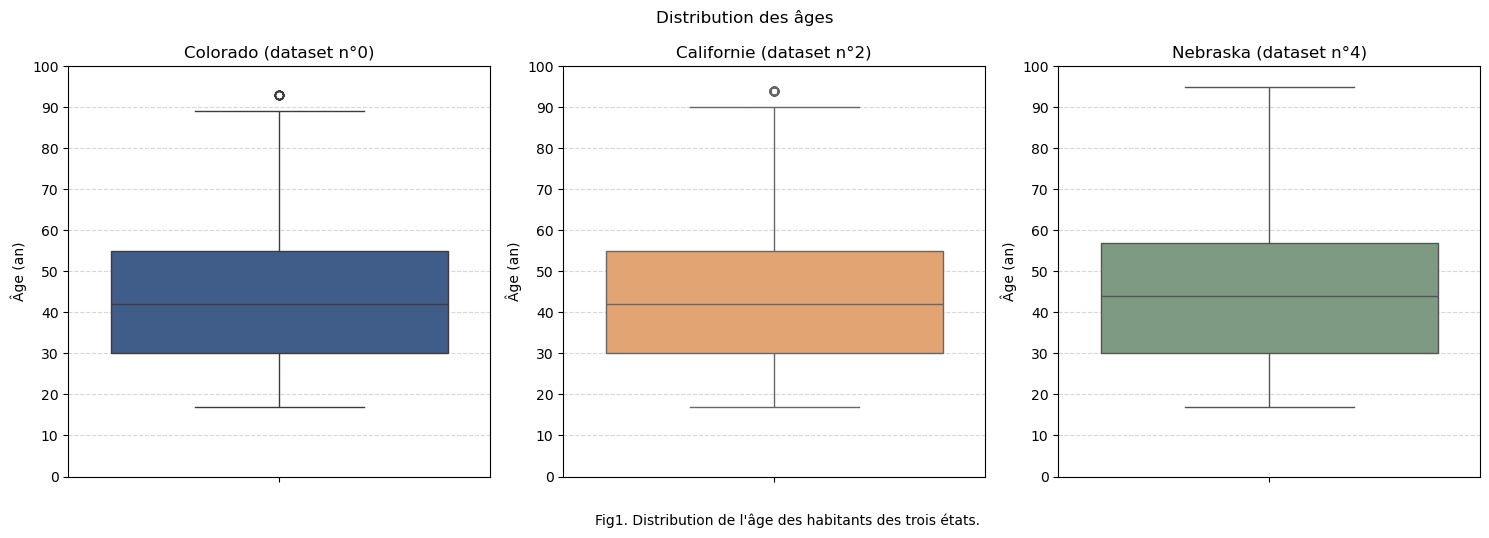

In [62]:
## Affichage de la distribution de l'âge dans les 3 états

fig, axes = plt.subplots(1, 3, figsize=(15, 5))

titres = ["Colorado (dataset n°0)", "Californie (dataset n°2)", "Nebraska (dataset n°4)"]
couleurs = ["#345995", "#F4A261", "#7A9E7E"]
colonne = "AGEP"

for ax, df, titre, couleur in zip(axes, [datasets[0], datasets[2], datasets[4]], titres, couleurs):
    sns.boxplot(y=df[colonne], ax=ax, color=couleur)
    ax.set_title(titre)
    ax.set_ylabel("Âge (an)")
    ax.grid(axis="y", linestyle="--", alpha=0.5)
    ax.set_yticks(range(0, 101, 10))

fig.suptitle("Distribution des âges")
plt.tight_layout()
plt.figtext(0.4, -0.05, "Fig1. Distribution de l'âge des habitants des trois états.")
plt.show()

Nous remarquons qu'il n'y a pas de valeurs aberrantes. De plus, l'âge minimum est autour de 18 ans. Il est peu étonnant de ne pas voir de jeunes enfants dans une étude sur le revenu.

<h5>COW : Catégorie d'emploi</h5>

La feature 'COW' (Class Of Worker) correspond à la catégorie d'emploi. Ces valeurs doivent évoluer entre 1 et 9.

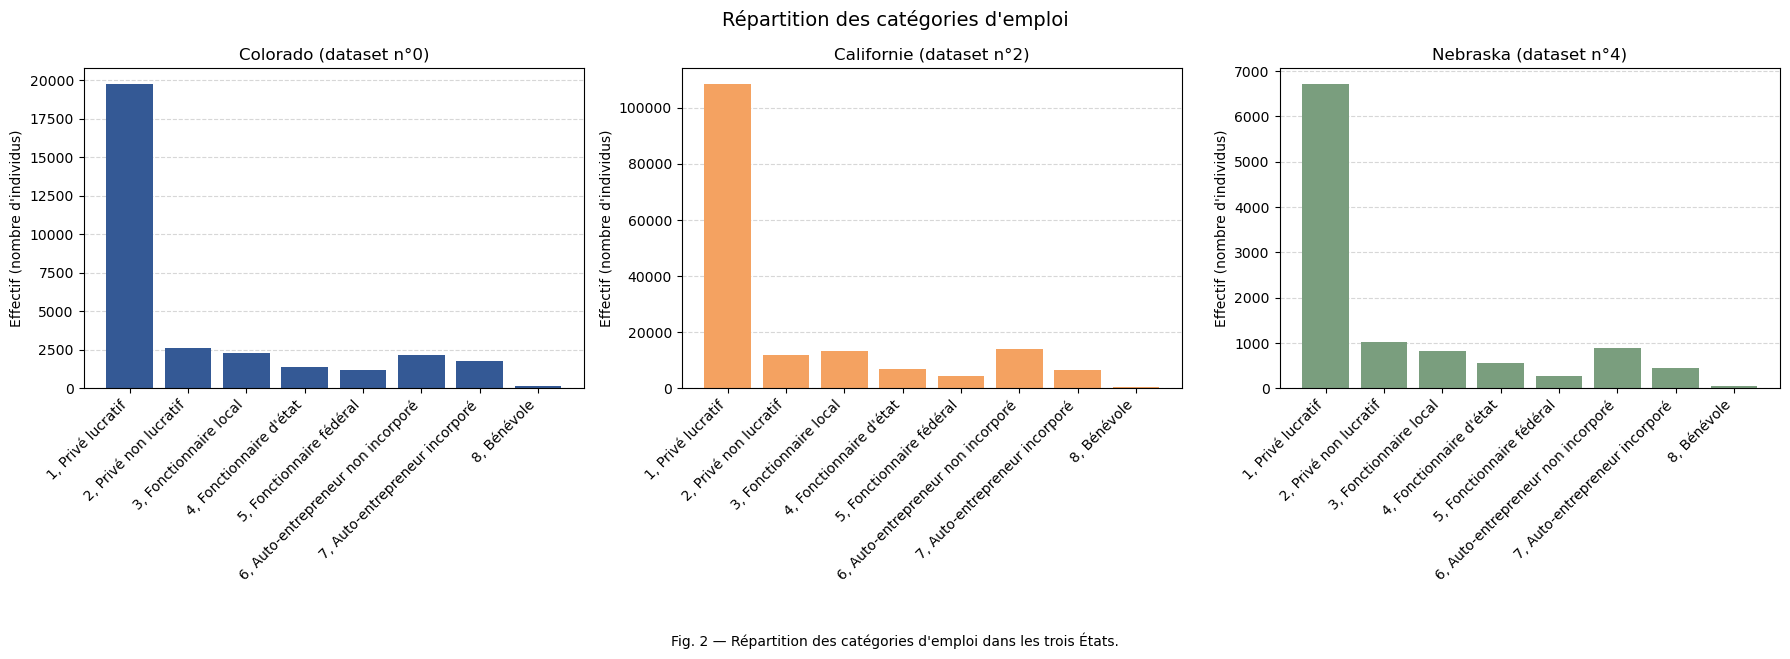

In [63]:
fig, axes = plt.subplots(1, 3, figsize=(18, 6))

colonne = "COW"

axe_x = {
    1.0: "1, Privé lucratif",
    2.0: "2, Privé non lucratif",
    3.0: "3, Fonctionnaire local",
    4.0: "4, Fonctionnaire d'état",
    5.0: "5, Fonctionnaire fédéral",
    6.0: "6, Auto-entrepreneur non incorporé",
    7.0: "7, Auto-entrepreneur incorporé",
    8.0: "8, Bénévole",
    9.0: "9, Sans emploi depuis 5 ans"
}

for ax, df, titre, couleur in zip(
    axes, [datasets[0], datasets[2], datasets[4]], titres, couleurs
):
    effectifs = df[colonne].value_counts().sort_index()
    labels = [axe_x.get(x, str(x)) for x in effectifs.index]
        

    ax.bar(range(len(effectifs)), effectifs.values, color = couleur)
    
    ax.set_xticks(range(len(effectifs)))
    ax.set_xticklabels(labels, rotation=45, ha="right")

    ax.set_title(titre)
    ax.set_ylabel("Effectif (nombre d'individus)")
    ax.grid(axis="y", linestyle="--", alpha=0.5)
    ax.set_axisbelow(True)

fig.suptitle("Répartition des catégories d'emploi", fontsize=14)
fig.text(0.5, -0.08, "Fig. 2 — Répartition des catégories d'emploi dans les trois États.", ha="center")

plt.tight_layout()
plt.show()

Les données provenant d'une étude cherchant à calculer le revenu moyen des individus, il n'est pas étonnant de voir qu'aucun dataset ne contient d'individu appartenant à la 9e catégorie (i.e. sans emploi depuis au moins 5 ans). 

<h5>SCHL : Études</h5>

La feature 'SCHL' (School) correspond à l'éducation. Les valeursdoivent être réparties dans 24 catégories différentes. Nous vérifions donc seulement que les valeurs sont bien des entiers compris entre 1 et 24 dans les 3 datasets.

In [64]:
## Vérification de valeurs aberrantes pour la feature SCHL

erreur = False

for i in [0, 2, 4]:
    try:
        assert datasets[i]["SCHL"].dropna().between(1, 24).all()
        assert (datasets[i]["SCHL"].dropna() % 1 == 0).all()
    except AssertionError:
        print(f"Le dataset n°{i} contient des valeurs aberrantes.")
        erreur = True

if not erreur:
    print("Aucun dataset n'a de valeur aberrante pour la feature 'SCHL'.")

Aucun dataset n'a de valeur aberrante pour la feature 'SCHL'.


<h5>MAR : Statut marital</h5>

La feature 'MAR' (Marital status) correspond au statut marital. Les possibilités sont réparties dans 5 catégories numérotées 1 à 5. Nous vérifions donc là encore l'absence de donées aberrantes.

In [65]:
## Vérification de valeurs aberrantes pour la feature SCHL

erreur = False

for i in [0, 2, 4]:
    try:
        assert datasets[i]["MAR"].dropna().between(1, 5).all()
        assert (datasets[i]["MAR"].dropna() % 1 == 0).all()
    except AssertionError:
        print(f"Le dataset n°{i} contient des valeurs aberrantes.")
        erreur = True

if not erreur:
    print("Aucun dataset n'a de valeur aberrante pour la feature 'SCHL'.")

Aucun dataset n'a de valeur aberrante pour la feature 'SCHL'.


<h5>OCCP : Occuaption (type d'emploi)</h5>

La feature 'OCCP' (Occupation) correspond au type d'emploi. Chaque type d'emploi est identifié par un code allant de 0010 à 9760. Certaines plages intermédiares ne sont pas non plus occupées selon la documentation. Nous vérifions donc qu'il n'y a pas de valeur aberrante.

In [66]:
## Vérification de valeurs aberrantes pour la feature OCCP

census_occupation_subcategories_2018 = {
    # Sous-catégories de "Management, Business, Science, and Arts Occupations" (0010-3550)
    "Management, Business, and Financial Occupations": [10, 960],  #[cite: 81]
    "Computer, Engineering, and Science Occupations": [1005, 1980],  #[cite: 82]
    "Education, Legal, Community Service, Arts, and Media Occupations": [2001, 2970],  #[cite: 84]
    "Healthcare Practitioners and Technical Occupations": [3000, 3550],  #[cite: 86]
   
    # Sous-catégories de "Service Occupations" (3601-4655)
    "Healthcare Support Occupations": [3601, 3655],  #[cite: 87]
    "Protective Service Occupations": [3700, 3960],  #[cite: 87]
    "Food Preparation and Serving Related Occupations": [4000, 4160],  #[cite: 88]
    "Building and Grounds Cleaning and Maintenance Occupations": [4200, 4255],  #[cite: 88]
    "Personal Care and Service Occupations": [4330, 4655],  #[cite: 88]
   
    # Sous-catégories de "Sales and Office Occupations" (4700-5940)
    "Sales and Related Occupations": [4700, 4965],  #[cite: 89]
    "Office and Administrative Support Occupations": [5000, 5940],  #[cite: 89]
   
    # Sous-catégories de "Natural Resources, Construction, and Maintenance Occupations" (6005-7640)
    "Farming, Fishing, and Forestry Occupations": [6005, 6130],  #[cite: 90]
    "Construction and Extraction Occupations": [6200, 6950],  #[cite: 91]
    "Installation, Maintenance, and Repair Occupations": [7000, 7640],  #[cite: 92]
   
    # Sous-catégories de "Production, Transportation, and Material Moving Occupations" (7700-9760)
    "Production Occupations": [7700, 8990],  #[cite: 93]
    "Transportation and Material Moving Occupations": [9005, 9760],  #[cite: 94]
   
    # Catégorie militaire
    "Military Specific Occupations": [9800, 9830],  #[cite: 95]
}

erreur = False

for i in [0, 2, 4]:
    try:
        occp = datasets[i]["OCCP"].dropna()

        assert occp.apply(
            lambda x: any(debut <= x <= fin for debut, fin in census_occupation_subcategories_2018.values())).all()

    except AssertionError:
        print(f"Le dataset n°{i} contient des valeurs OCCP hors des plages définies.")
        erreur = True

if not erreur:
    print("Aucun dataset n'a de valeur aberrante pour la feature OCCP.")

Aucun dataset n'a de valeur aberrante pour la feature OCCP.


<h5>POBP : Lieu de naissance</h5>

La feature 'POBP' (Place Of Birth) correspond au lei de naissance. Le lieu de naissance correspond à un pays ou un état/région. Ces codes évoluent de 1 à 999 avec des valeurs non utilisées. Nous vérifions encore qu'il n'y a pas de donnée aberrante.

In [67]:
## Vérification de valeurs aberrantes pour la feature POBP

ancestry_codes = {
    'WESTERN EUROPE (EXCEPT SPAIN)': [[1, 99], []],
    'EASTERN EUROPE AND FORMER SOVIET UNION': [[100, 180], [110, 121, 134, 135, 136, 137, 138, 139, 141, 149, 151, 162, 166]],
    'EUROPE, N.E.C.': [[181, 199], [182, 184, 186, 188, 189, 192, 197, 198, 199]],
    'HISPANIC CATEGORIES (INCLUDING SPAIN)': [[200, 299], [209, 216, 217, 220, 228, 230, 240, 241, 242, 243, 244, 245, 246, 247, 253, 254, 255, 256, 257, 258, 259, 260, 262, 263, 264, 265, 266, 267, 268, 269, 270, 272, 273, 274, 276, 277, 278, 279, 280, 281, 282, 283, 284, 285, 286, 287, 288, 289, 296, 297, 298, 299]],
    'WEST INDIES (EXCEPT HISPANIC)': [[300, 359], [305, 306, 307, 309, 313, 337, 338, 339, 340, 341, 342, 343, 344, 345, 346, 347, 348, 349, 350, 351, 352, 353, 354, 355, 356, 357, 358, 359]],
    'CENTRAL AND SOUTH AMERICA (EXCEPT HISPANIC)': [[360, 399], [361, 362, 363, 364, 366, 367, 368, 369, 371, 372, 373, 374, 376, 377, 378, 379, 381, 382, 383, 384, 385, 386, 387, 388, 389, 390, 391, 392, 393, 394, 395, 396, 397, 398, 399]],
    'NORTH AFRICA AND SOUTH WEST ASIA': [[400, 499], [401, 403, 405, 409, 410, 418, 420, 424, 426, 428, 430, 432, 433, 440, 443, 445, 446, 447, 448, 449, 450, 451, 452, 453, 454, 455, 456, 457, 458, 459, 460, 461, 462, 463, 464, 468, 469, 472, 473, 474, 475, 476, 477, 478, 479, 481, 482, 486, 487, 488, 489, 491, 492, 493, 494, 497, 498, 499]],
    'SUBSAHARAN AFRICA': [[500, 599], [501, 503, 505, 507, 509, 511, 514, 517, 518, 524, 526, 528, 533, 535, 536, 537, 539, 540, 542, 544, 548, 552, 559, 560, 562, 563, 565, 567, 575, 581, 585, 587]],
    'SOUTH ASIA': [[600, 699], [604, 605, 606, 608, 610, 611, 612, 613, 614, 617, 619, 621, 623, 625, 627, 629, 631, 633, 635, 637, 639, 641, 643, 645, 647, 649, 651, 653, 655, 657, 659, 660, 661, 662, 663, 664, 665, 666, 667, 668, 669, 670, 671, 672, 673, 674, 676, 677, 678, 679, 681, 682, 683, 684, 685, 686, 687, 688, 689, 693, 694, 696, 697, 698, 699]],
    'OTHER ASIA': [[700, 799], [701, 705, 710, 711, 713, 715, 717, 719, 721, 722, 723, 724, 725, 726, 727, 728, 729, 731, 733, 735, 737, 738, 739, 747, 749, 751, 752, 753, 754, 755, 756, 757, 758, 759, 760, 761, 762, 763, 764, 767, 769, 772, 773, 775, 779, 780, 781, 784, 789, 791, 796, 797, 798, 799]],
    'PACIFIC': [[800, 899], [806, 807, 812, 835, 836, 837, 838, 839, 842, 848, 849, 851, 852, 853, 854, 855, 856, 857, 858, 859, 861, 863, 864, 865, 866, 867, 868, 869, 870, 871, 872, 873, 874, 875, 876, 877, 878, 879, 880, 881, 882, 883, 884, 885, 886, 887, 888, 889, 890, 891, 892, 893, 894, 895, 896, 897, 898, 899]],
    'NORTH AMERICA (EXCEPT HISPANIC)': [[900, 994], [909, 910, 911, 912, 915, 916, 926, 932, 938, 975, 992]],
    'RESIDUAL AND NO RESPONSE': [[995, 999], [997]],
}

erreur = False

for i in [0, 2, 4]:
    pobp = datasets[i]["POBP"].dropna()

    valeurs_interdites = set()
    debut_residual, fin_residual = ancestry_codes["RESIDUAL AND NO RESPONSE"][0]

    for categorie, (plage, exclusions) in ancestry_codes.items():
        if categorie != "RESIDUAL AND NO RESPONSE":
            valeurs_interdites.update(exclusions)

    valeurs_trouvees = sorted(pobp[pobp.isin(valeurs_interdites)].unique())

    if valeurs_trouvees:
        print(f"Dataset n°{i} : Nombre de valeurs POBP non attribuées : {len(valeurs_trouvees)}")
        erreur = True

    valeurs_residual = sorted(
        pobp[pobp.between(debut_residual, fin_residual)].unique()
    )

    if valeurs_residual:
        print(f"Dataset n°{i} : Nombre de valeurs 'Residual and no response' : {len(valeurs_residual)}")

if not erreur:
    print("Aucun dataset n'a de valeur aberrante pour la feature POBP.")

Dataset n°0 : Nombre de valeurs POBP non attribuées : 43
Dataset n°2 : Nombre de valeurs POBP non attribuées : 57
Dataset n°4 : Nombre de valeurs POBP non attribuées : 28


Nous remarquons qu'un certain nombre d'individus sont associés à des lieux de naissance non identifiés. Cependant, il s'agit uniquement de non attribués appartenant à des catégories de régions, et non à la catégorie 'RESIDUAL AND NO RESPONSE'.

Comme une telle précision sur les lieux de naissance n'est pas nécessaire à notre étude, nous prévoyons de toute manière d'ultérieurement regrouper les lieux de naissances dans les grandes catégories (régions du monde) présentes dans la documentation. Aussi, les individus ayant des lieux de naissance non définis mais correctement enregistrés comme appartenant à une région du monde ne causeront pas de problèmes.

<h5>RELP : Relation à l'individu de référence</h5>

Dû à la manière dont ont été collectés les données, certains individus sont des 'référents'. La relation d'un individu avec son référent est décrit dans la feature RELP (Relationship). Il s'agit de catégories allant de 0 (référent) à 17. Il nous suffit donc de vérifier que les données appartiennent bien à ces bornes.

In [68]:
## Vérification de valeurs aberrantes pour la feature RELP

erreur = False

for i in [0, 2, 4]:
    try:
        assert datasets[i]["RELP"].dropna().between(0, 17).all()
        assert (datasets[i]["RELP"].dropna() % 1 == 0).all()
    except AssertionError:
        print(f"Le dataset n°{i} contient des valeurs aberrantes.")
        erreur = True

if not erreur:
    print("Aucun dataset n'a de valeur aberrante pour la feature 'RELP'.")

Aucun dataset n'a de valeur aberrante pour la feature 'RELP'.


<h5>WKHP : Nombre d'heures de travail hebdomadaires</h5>

La feature WKHP (Work hours) indique le nombre usuel d'heures de travail hebdomadaires des individus sur les 12 dernier mois. Les données sont numériques indiquant directement le nombre d'heures. On note cependant que la documentation indique un cap à 99 (les valeurs supérieures ont été réduites à 99). Il suffit dont ce vérifier que les valeurs sont comprises entre 1 et 99.

In [69]:
## Vérification de valeurs aberrantes pour la feature WKHP

erreur = False

for i in [0, 2, 4]:
    try:
        assert datasets[i]["WKHP"].dropna().between(1, 99).all()
        assert (datasets[i]["WKHP"].dropna() % 1 == 0).all()
    except AssertionError:
        print(f"Le dataset n°{i} contient des valeurs aberrantes.")
        erreur = True

if not erreur:
    print("Aucun dataset n'a de valeur aberrante pour la feature 'WKHP'.")

Aucun dataset n'a de valeur aberrante pour la feature 'WKHP'.


<h5>SEX : Sexe</h5>

La feature SEX correspond au sexe des individus. Il vaut 1 pour un homme ou 2 pour une femme. Nous vérifions que les données correspondent.

In [70]:
## Vérification de valeurs aberrantes pour la feature SEX

erreur = False

for i in [0, 2, 4]:
    try:
        assert datasets[i]["SEX"].dropna().between(1, 2).all()
        assert (datasets[i]["SEX"].dropna() % 1 == 0).all()
    except AssertionError:
        print(f"Le dataset n°{i} contient des valeurs aberrantes.")
        erreur = True

if not erreur:
    print("Aucun dataset n'a de valeur aberrante pour la feature 'SEX'.")

Aucun dataset n'a de valeur aberrante pour la feature 'SEX'.


<h5>RAC1P : Ethnie</h5>

La feature RAC1P correspond à l'ethnie des individus. Elle est catégorisée en 9 groupes codés de 1 à 9. Nous vérifions.

In [71]:
## Vérification de valeurs aberrantes pour la feature RAC1P

erreur = False

for i in [0, 2, 4]:
    try:
        assert datasets[i]["RAC1P"].dropna().between(1, 9).all()
        assert (datasets[i]["RAC1P"].dropna() % 1 == 0).all()
    except AssertionError:
        print(f"Le dataset n°{i} contient des valeurs aberrantes.")
        erreur = True

if not erreur:
    print("Aucun dataset n'a de valeur aberrante pour la feature 'RAC1P'.")

Aucun dataset n'a de valeur aberrante pour la feature 'RAC1P'.


Nous avons vérifiés qu'il n'y avait pas de données aberrantes problématiques dans les jeux de données des features.

<h4>I.2.B. Label</h4>

Le but de l'étude dont provient les jeux de données est de savoir si le salaire annuel d'un individu est supérieur à 50000 dollars. Ainsi, le label PINCP (Personal Income) indique si un individu possède un salaire annuel supérieur ou non à 50000 dollars.

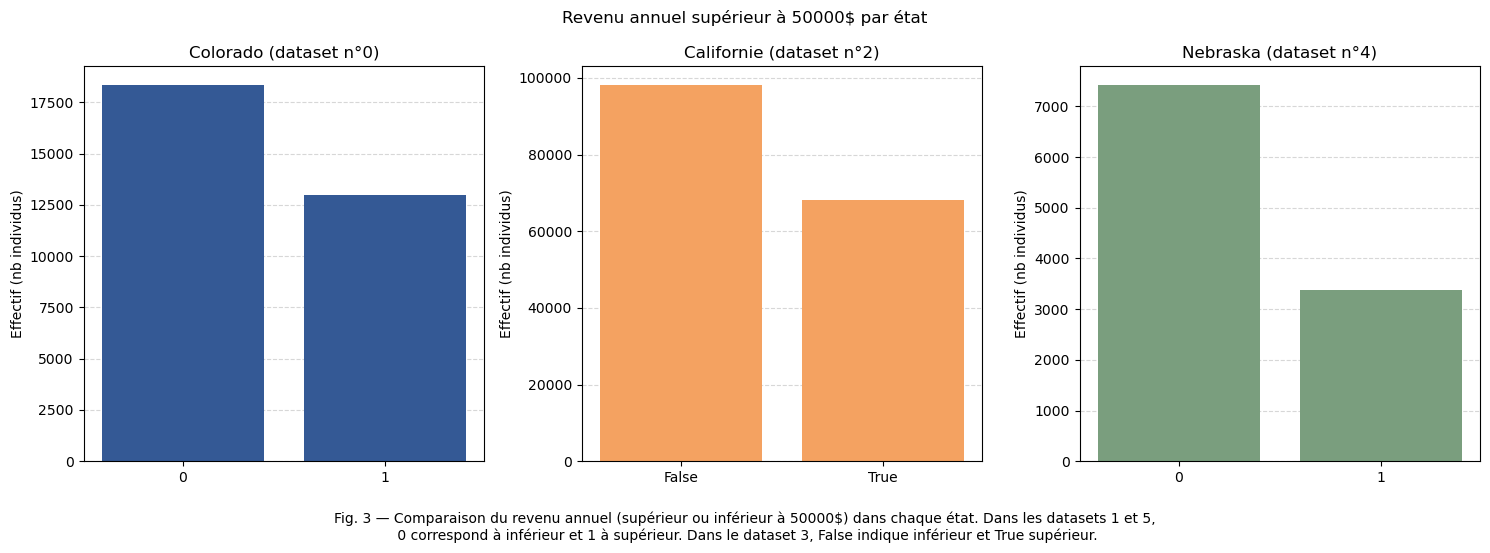

In [72]:
## Affichage répartition des labels dans les 3 états

fig, axes = plt.subplots(1, 3, figsize=(15, 5))

config = [
    (datasets[1], titres[0], [0, 1], couleurs[0]),
    (datasets[3], titres[1], [False, True], couleurs[1]),
    (datasets[5], titres[2], [0, 1], couleurs[2])
]

for ax, (df, titre, labels, couleur) in zip(axes, config):
    effectifs = df["PINCP"].value_counts().reindex(labels, fill_value=0)

    ax.bar([str(x) for x in labels], effectifs.values, color=couleur)

    ax.set_title(titre)
    ax.set_ylabel("Effectif (nb individus)")
    ax.grid(axis="y", linestyle="--", alpha=0.5)
    ax.set_axisbelow(True)

fig.suptitle("Revenu annuel supérieur à 50000$ par état")
plt.tight_layout()
fig.text(0.5, -0.08, "Fig. 3 — Comparaison du revenu annuel (supérieur ou inférieur à 50000$) dans chaque état. Dans les datasets 1 et 5,\n 0 correspond à inférieur et 1 à supérieur. Dans le dataset 3, False indique inférieur et True supérieur.", ha="center")

plt.show()

On remarque immédiatement que les trois datasets n'utilisent pas le même format. Les datasets n°1 et 5 utilisent un format numérique tandis que le dataset n°3 utilise des booléens. Nous changeons donc les valeurs du dataset n°3 en les valeurs numériques 0 et 1 correspondantes.

In [73]:
datasets[3] = datasets[3].replace({False: 0, True: 1})

/tmp/ipykernel_5906/2921033429.py:1: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  datasets[3] = datasets[3].replace({False: 0, True: 1})


<h4>I.2.C Correspondance features/labels</h4>

Enfin, nous vérifions que le nombre d'individus entre les datasets des features et les datasets des labels correspondants sont bien égaux.

In [74]:
for i in [0, 2, 4]:
    try:
        assert len(datasets[i]) == len(datasets[i+1])
    except AssertionError:
        print(f"Erreur : datasets[{i}] et datasets[{i+1}] n'ont pas le même nombre d'individus.")

if all(len(datasets[i]) == len(datasets[i+1]) for i in [0, 2, 4]):
    print("Tous les datasets features et labels correspondant ont le même nombre d'individus.")

Tous les datasets features et labels correspondant ont le même nombre d'individus.


<h3>I.3 Reformattage de certaines données</h3>

Comme nous l'avons dit précédemment pour la feature POBP, un trop grand nombre de catégories nous paraît inintéressant en vue de notre objectif. Nous décidons donc de réduire les features POBP et OCCP a leur grande catégorie. Pour cela, nous créons deux nouvelles features nPOBP et nOCCP correspondantes. Nous ne ferons pas d'analyse sur les features POBP et OCCP par la suite.

In [75]:
def categoriser_POBP(x):
    if pd.isna(x):
        return np.nan

    for i, (nom, (plage, exclusions)) in enumerate(ancestry_codes.items(), start=1):
        debut, fin = plage

        if debut <= x <= fin:
            if nom == "RESIDUAL AND NO RESPONSE":
                return np.nan
            return i

    return np.nan


def categoriser_OCCP(x):
    if pd.isna(x):
        return np.nan

    for i, (nom, (debut, fin)) in enumerate(
        census_occupation_subcategories_2018.items(), start=1
    ):
        if debut <= x <= fin:
            return i

    return np.nan


for i in [0, 2, 4]:
    datasets[i]["nPOBP"] = datasets[i]["POBP"].apply(categoriser_POBP)
    datasets[i]["nOCCP"] = datasets[i]["OCCP"].apply(categoriser_OCCP)

<h2>II. Analyse globale</h2>

Nous commençons, en vue de notre objectif de comparer l'analyse dans les 3 états, par observer les différences d'effectif total entre les trois datasets.

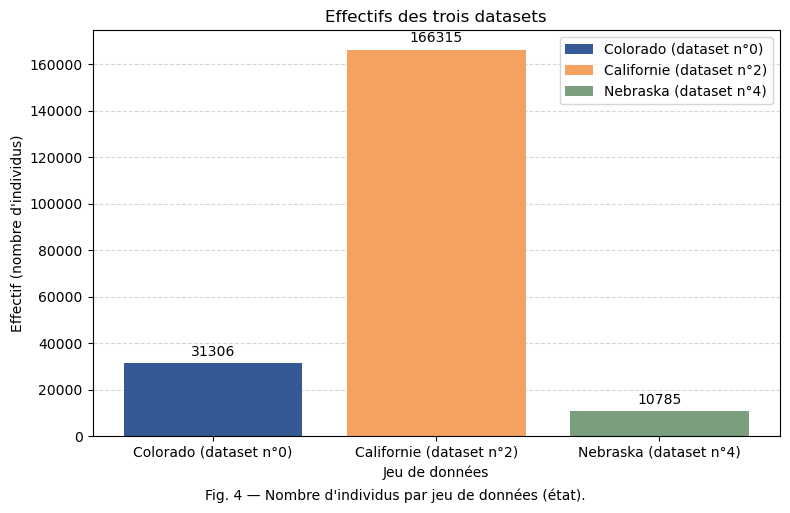

In [76]:
effectifs = [len(datasets[i]) for i in [0,2,4]]

fig, ax = plt.subplots(figsize=(8, 5))
barres = ax.bar(titres, effectifs, color=couleurs)

ax.bar_label(barres, fmt="%.0f", padding=3)

ax.set_title("Effectifs des trois datasets")
ax.set_xlabel("Jeu de données")
ax.set_ylabel("Effectif (nombre d'individus)")
ax.grid(axis="y", linestyle="--", alpha=0.5)
ax.set_axisbelow(True)

ax.legend(barres, titres)

fig.text(0.5, -0.01, "Fig. 4 — Nombre d'individus par jeu de données (état).", ha="center")
plt.tight_layout()
plt.show()

La Fig.4 illustre une différence d'effectif très importante entre les données des 3 états, il y a plus de 10 fois plus de données provenant de Californie que du Nebraska. Par la suite, pour certaines comparaisons, il faudra se rappeler de normaliser les données.

<h2>III. Analyse univariée</h2>

Nous analysons une à une les valeurs des différentes features, en observant les différences entre les 3 états.

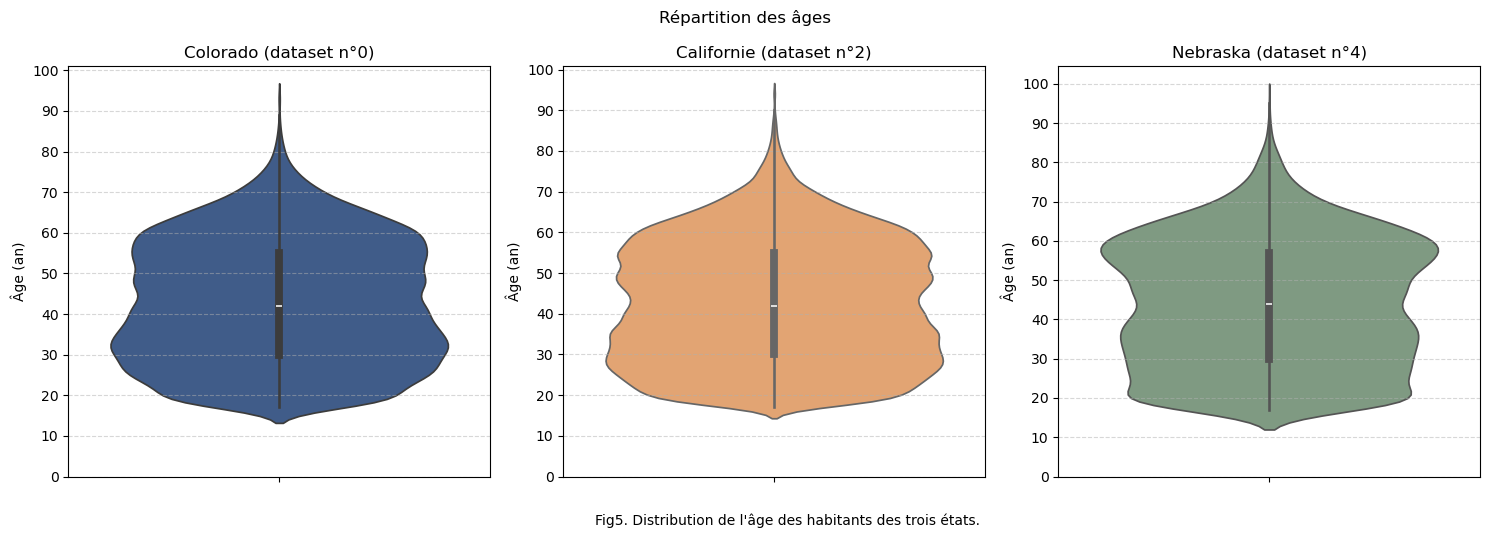

In [77]:
## Affichage de la distribution de l'âge dans les 3 états

fig, axes = plt.subplots(1, 3, figsize=(15, 5))

colonne = "AGEP"

for ax, df, titre, couleur in zip(axes, [datasets[0], datasets[2], datasets[4]], titres, couleurs):
    sns.violinplot(y=df[colonne], ax=ax, color = couleur)
    ax.set_title(titre)
    ax.set_ylabel("Âge (an)")
    ax.grid(axis="y", linestyle="--", alpha=0.5)
    ax.set_yticks(range(0, 101, 10))

fig.suptitle("Répartition des âges")
plt.tight_layout()
plt.figtext(0.4, -0.05, "Fig5. Distribution de l'âge des habitants des trois états.")
plt.show()

On remarque dans la figure Fig.5 que les distributions des âges sont très similaires au Colorado et en Californie, mais qu'il y a une différence plus importante au Nebraska, une population plus vieille.


Pour la catégorie d'emploi, nous nous référons à la figure Fig.2 (voir plus haut). Celle-ci nous montre une distribution similaire dans les 3 états, avec une majorité d'employés dans le privé à but lucratif, ce qui fait sens dans une société capitaliste. On peut aussi voir 

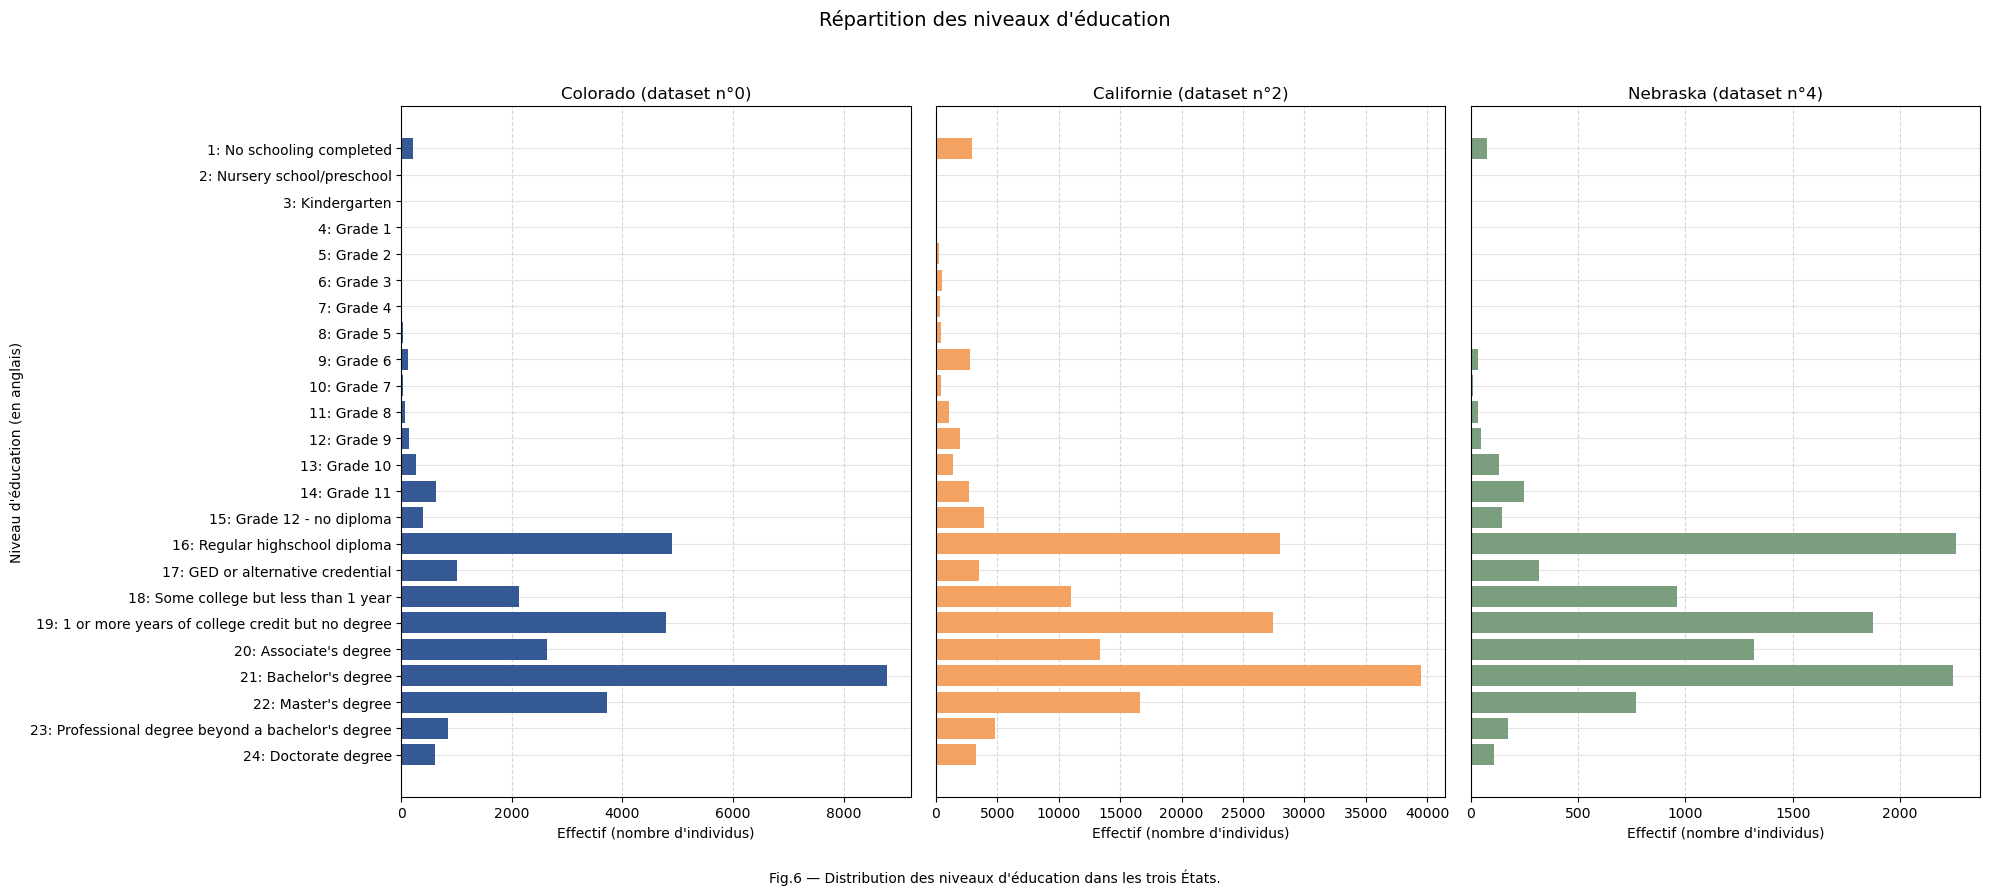

In [78]:
fig, axes = plt.subplots(1, 3, figsize=(20, 9), sharey=True)

colonne = "SCHL"

axe_x = {
    1.0: "1: No schooling completed",
    2.0: "2: Nursery school/preschool",
    3.0: "3: Kindergarten",
    4.0: "4: Grade 1",
    5.0: "5: Grade 2",
    6.0: "6: Grade 3",
    7.0: "7: Grade 4",
    8.0: "8: Grade 5",
    9.0: "9: Grade 6",
    10.0: "10: Grade 7",
    11.0: "11: Grade 8",
    12.0: "12: Grade 9",
    13.0: "13: Grade 10",
    14.0: "14: Grade 11",
    15.0: "15: Grade 12 - no diploma",
    16.0: "16: Regular highschool diploma",
    17.0: "17: GED or alternative credential",
    18.0: "18: Some college but less than 1 year",
    19.0: "19: 1 or more years of college credit but no degree",
    20.0: "20: Associate's degree",
    21.0: "21: Bachelor's degree",
    22.0: "22: Master's degree",
    23.0: "23: Professional degree beyond a bachelor's degree",
    24.0: "24: Doctorate degree"
}

# Conserver toutes les catégories dans le même ordre
categories = list(axe_x.keys())
labels = list(axe_x.values())
positions = range(len(categories))

for j, (ax, df, titre, couleur) in enumerate(
    zip(axes, [datasets[0], datasets[2], datasets[4]], titres, couleurs)
):
    effectifs = df[colonne].value_counts().reindex(categories, fill_value=0)

    ax.barh(positions, effectifs.values, color=couleur)

    ax.set_title(titre)
    ax.set_xlabel("Effectif (nombre d'individus)")
    ax.grid(axis="x", linestyle="--", alpha=0.5)
    ax.set_axisbelow(True)
    ax.grid(axis="y", color="lightgray", linestyle="-", alpha=0.6)


    # Afficher les noms uniquement à gauche
    ax.set_yticks(list(positions))
    if j == 0:
        ax.set_yticklabels(labels)
        ax.set_ylabel("Niveau d'éducation (en anglais)")

    else:
        ax.tick_params(axis="y", left=False, labelleft=False)

# Inverser l'ordre pour afficher la catégorie 1 en haut
axes[0].invert_yaxis()

fig.suptitle("Répartition des niveaux d'éducation", fontsize=14)
fig.text(
    0.5, 0.01,
    "Fig.6 — Distribution des niveaux d'éducation dans les trois États.",
    ha="center"
)

plt.tight_layout(rect=[0, 0.04, 1, 0.95])
plt.show()

On observe dans la figure Fig.6 une distribution similaire du niveau d'étude dans les trois jeux de données.

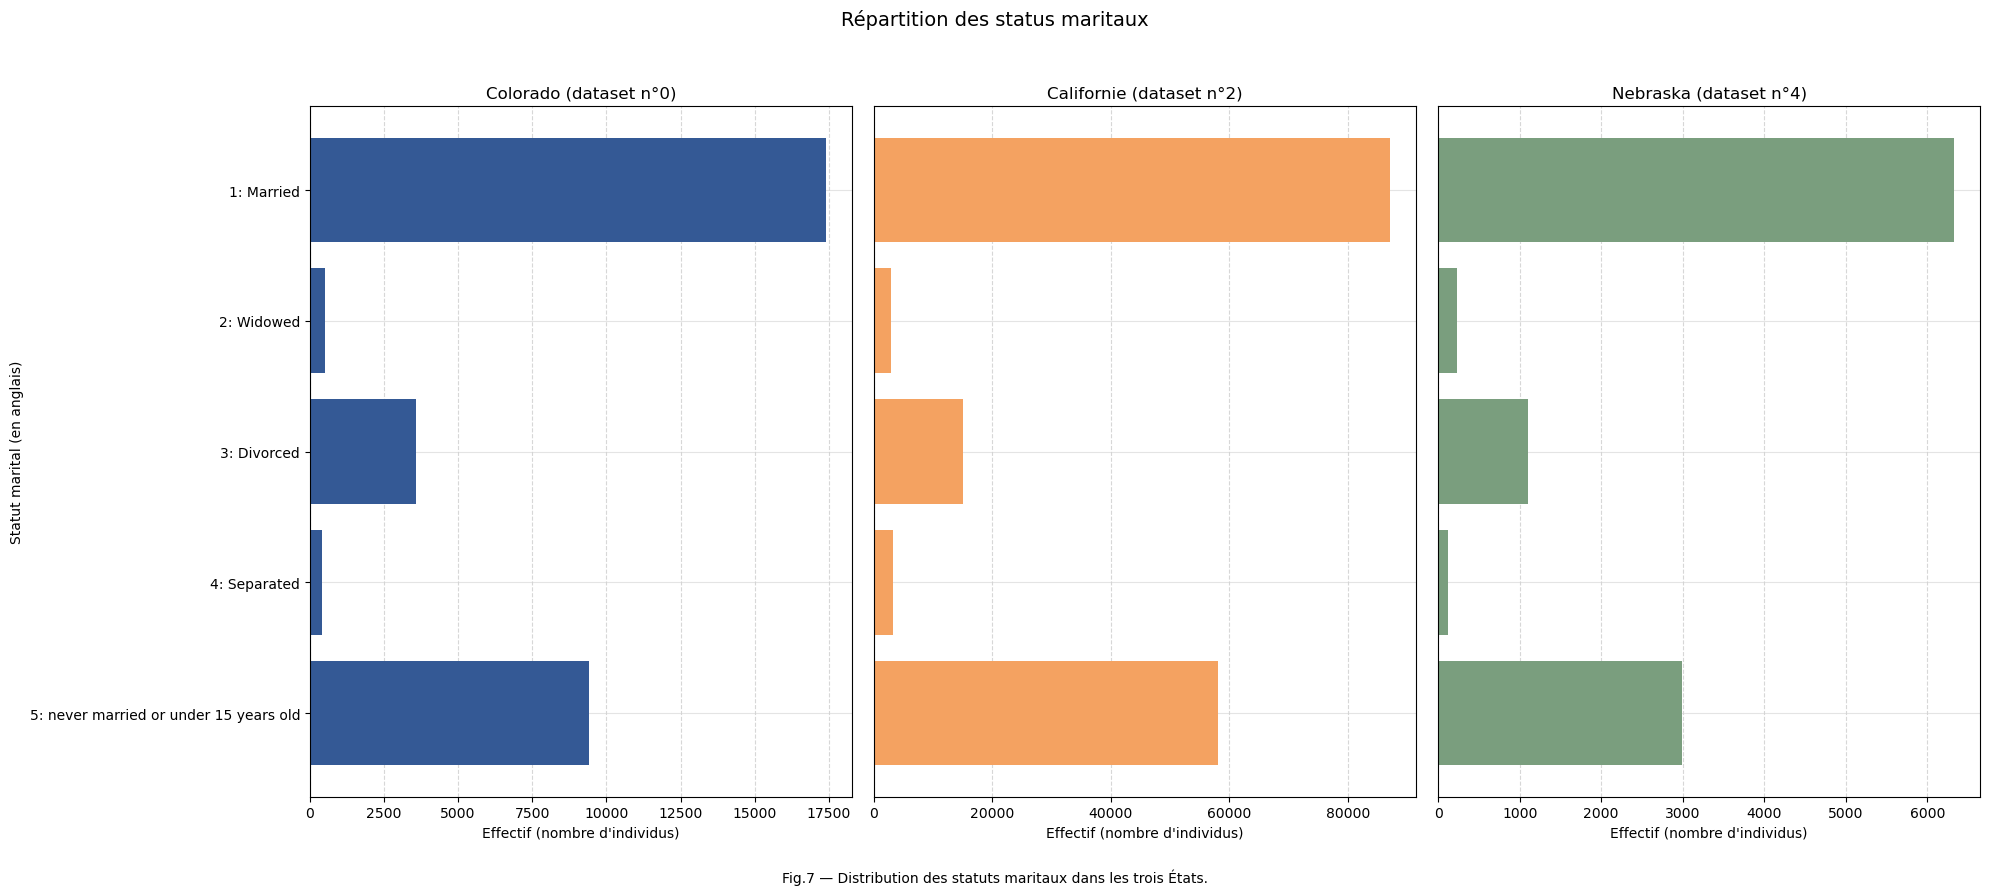

In [79]:
fig, axes = plt.subplots(1, 3, figsize=(20, 9), sharey=True)

colonne = "MAR"

axe_x = {
    1.0: "1: Married",
    2.0: "2: Widowed",
    3.0: "3: Divorced",
    4.0: "4: Separated",
    5.0: "5: never married or under 15 years old"
}

# Conserver toutes les catégories dans le même ordre
categories = list(axe_x.keys())
labels = list(axe_x.values())
positions = range(len(categories))

for j, (ax, df, titre, couleur) in enumerate(
    zip(axes, [datasets[0], datasets[2], datasets[4]], titres, couleurs)
):
    effectifs = df[colonne].value_counts().reindex(categories, fill_value=0)

    ax.barh(positions, effectifs.values, color=couleur)

    ax.set_title(titre)
    ax.set_xlabel("Effectif (nombre d'individus)")
    ax.grid(axis="x", linestyle="--", alpha=0.5)
    ax.set_axisbelow(True)
    ax.grid(axis="y", color="lightgray", linestyle="-", alpha=0.6)


    # Afficher les noms uniquement à gauche
    ax.set_yticks(list(positions))
    if j == 0:
        ax.set_yticklabels(labels)
        ax.set_ylabel("Statut marital (en anglais)")

    else:
        ax.tick_params(axis="y", left=False, labelleft=False)

# Inverser l'ordre pour afficher la catégorie 1 en haut
axes[0].invert_yaxis()

fig.suptitle("Répartition des status maritaux", fontsize=14)
fig.text(
    0.5, 0.01,
    "Fig.7 — Distribution des statuts maritaux dans les trois États.",
    ha="center"
)

plt.tight_layout(rect=[0, 0.04, 1, 0.95])
plt.show()

On remarque dans la figure Fig.7 que la distribution des statuts maritaux est similaire dans les trois États.

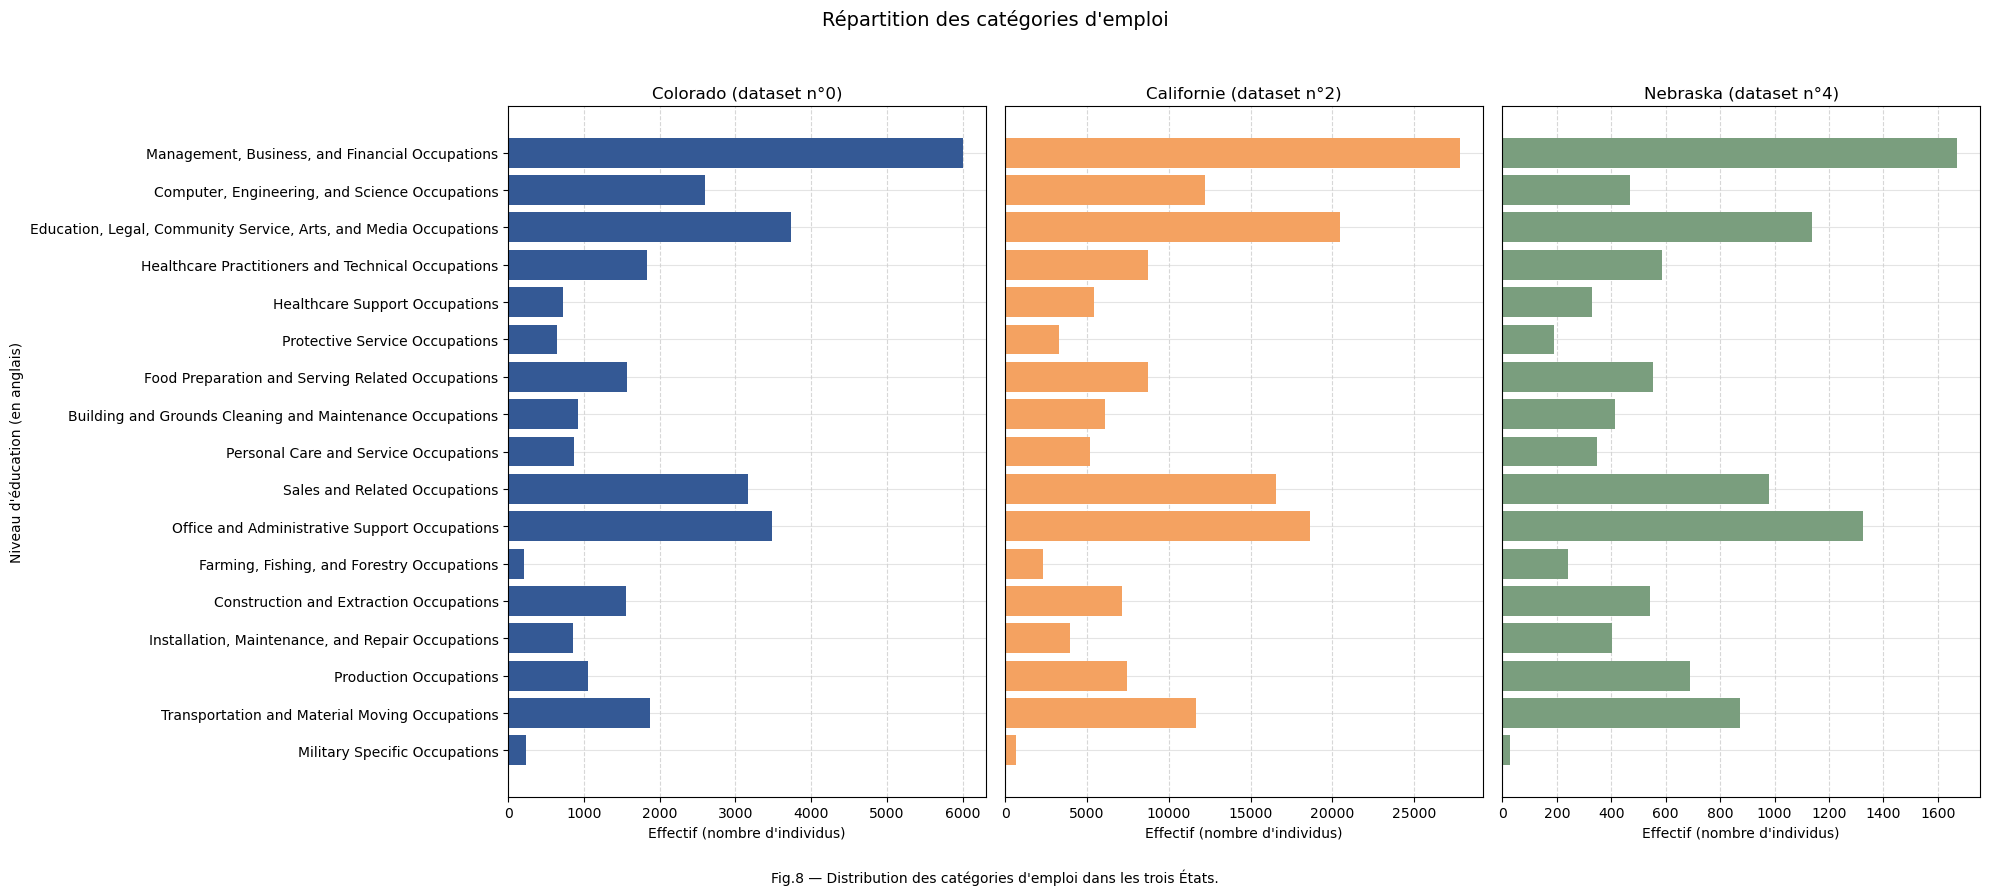

In [80]:
fig, axes = plt.subplots(1, 3, figsize=(20, 9), sharey=True)

colonne = "nOCCP"

axe_x = {
    i: nom
    for i, nom in enumerate(census_occupation_subcategories_2018.keys(), start=1)
}

# Conserver toutes les catégories dans le même ordre
categories = list(axe_x.keys())
labels = list(axe_x.values())
positions = range(len(categories))

for j, (ax, df, titre, couleur) in enumerate(
    zip(axes, [datasets[0], datasets[2], datasets[4]], titres, couleurs)
):
    effectifs = df[colonne].value_counts().reindex(categories, fill_value=0)

    ax.barh(positions, effectifs.values, color=couleur)

    ax.set_title(titre)
    ax.set_xlabel("Effectif (nombre d'individus)")
    ax.grid(axis="x", linestyle="--", alpha=0.5)
    ax.set_axisbelow(True)
    ax.grid(axis="y", color="lightgray", linestyle="-", alpha=0.6)


    # Afficher les noms uniquement à gauche
    ax.set_yticks(list(positions))
    if j == 0:
        ax.set_yticklabels(labels)
        ax.set_ylabel("Niveau d'éducation (en anglais)")

    else:
        ax.tick_params(axis="y", left=False, labelleft=False)

# Inverser l'ordre pour afficher la catégorie 1 en haut
axes[0].invert_yaxis()

fig.suptitle("Répartition des catégories d'emploi", fontsize=14)
fig.text(
    0.5, 0.01,
    "Fig.8 — Distribution des catégories d'emploi dans les trois États.",
    ha="center"
)

plt.tight_layout(rect=[0, 0.04, 1, 0.95])
plt.show()

On observe à nouveau sur la figure Fig.8 une distribution similaire entre les trois États.

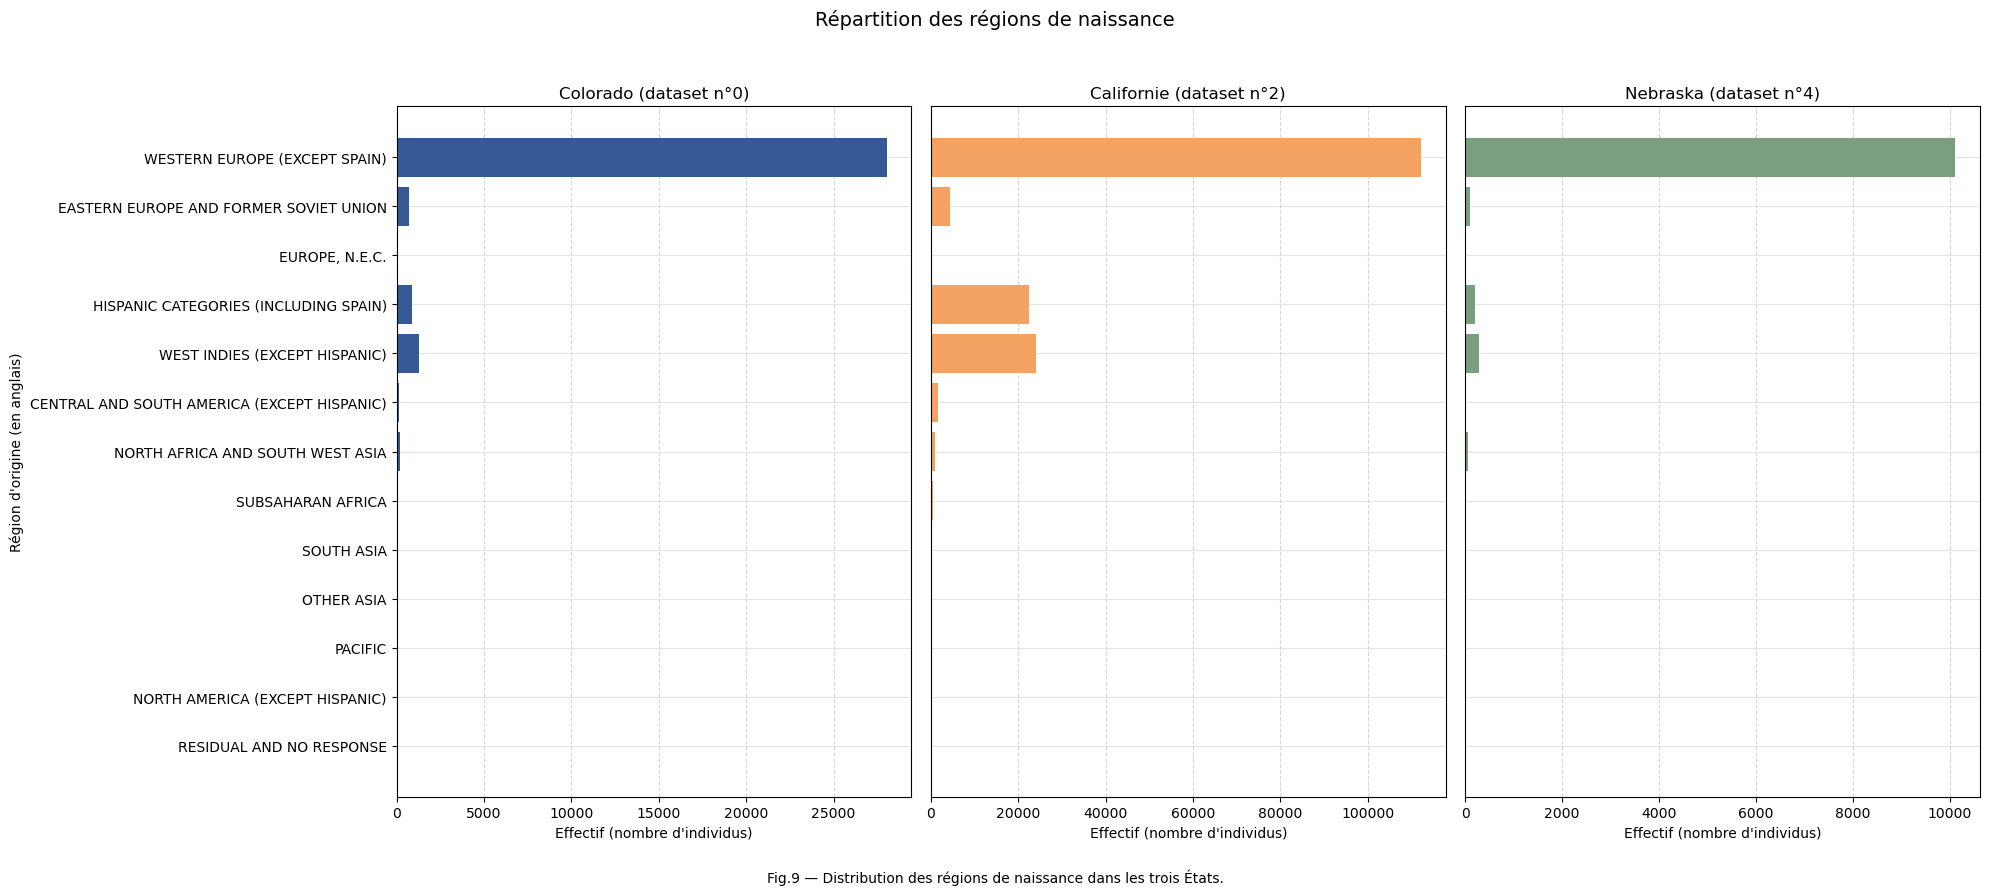

In [81]:
fig, axes = plt.subplots(1, 3, figsize=(20, 9), sharey=True)

colonne = "nPOBP"

axe_x = {
    i: nom
    for i, nom in enumerate(ancestry_codes.keys(), start=1)
}

# Conserver toutes les catégories dans le même ordre
categories = list(axe_x.keys())
labels = list(axe_x.values())
positions = range(len(categories))

for j, (ax, df, titre, couleur) in enumerate(
    zip(axes, [datasets[0], datasets[2], datasets[4]], titres, couleurs)
):
    effectifs = df[colonne].value_counts().reindex(categories, fill_value=0)

    ax.barh(positions, effectifs.values, color=couleur)

    ax.set_title(titre)
    ax.set_xlabel("Effectif (nombre d'individus)")
    ax.grid(axis="x", linestyle="--", alpha=0.5)
    ax.set_axisbelow(True)
    ax.grid(axis="y", color="lightgray", linestyle="-", alpha=0.6)


    # Afficher les noms uniquement à gauche
    ax.set_yticks(list(positions))
    if j == 0:
        ax.set_yticklabels(labels)
        ax.set_ylabel("Région d'origine (en anglais)")

    else:
        ax.tick_params(axis="y", left=False, labelleft=False)

# Inverser l'ordre pour afficher la catégorie 1 en haut
axes[0].invert_yaxis()

fig.suptitle("Répartition des régions de naissance", fontsize=14)
fig.text(
    0.5, 0.01,
    "Fig.9 — Distribution des régions de naissance dans les trois États.",
    ha="center"
)

plt.tight_layout(rect=[0, 0.04, 1, 0.95])
plt.show()

On remarque dans la figure Fig9. une distribution similaire dans les trois États. On peut tout de même noter qu'il y a davantage d'individus originaires de pays hispaniques ou des antilles dans le jeu de données de Californie.

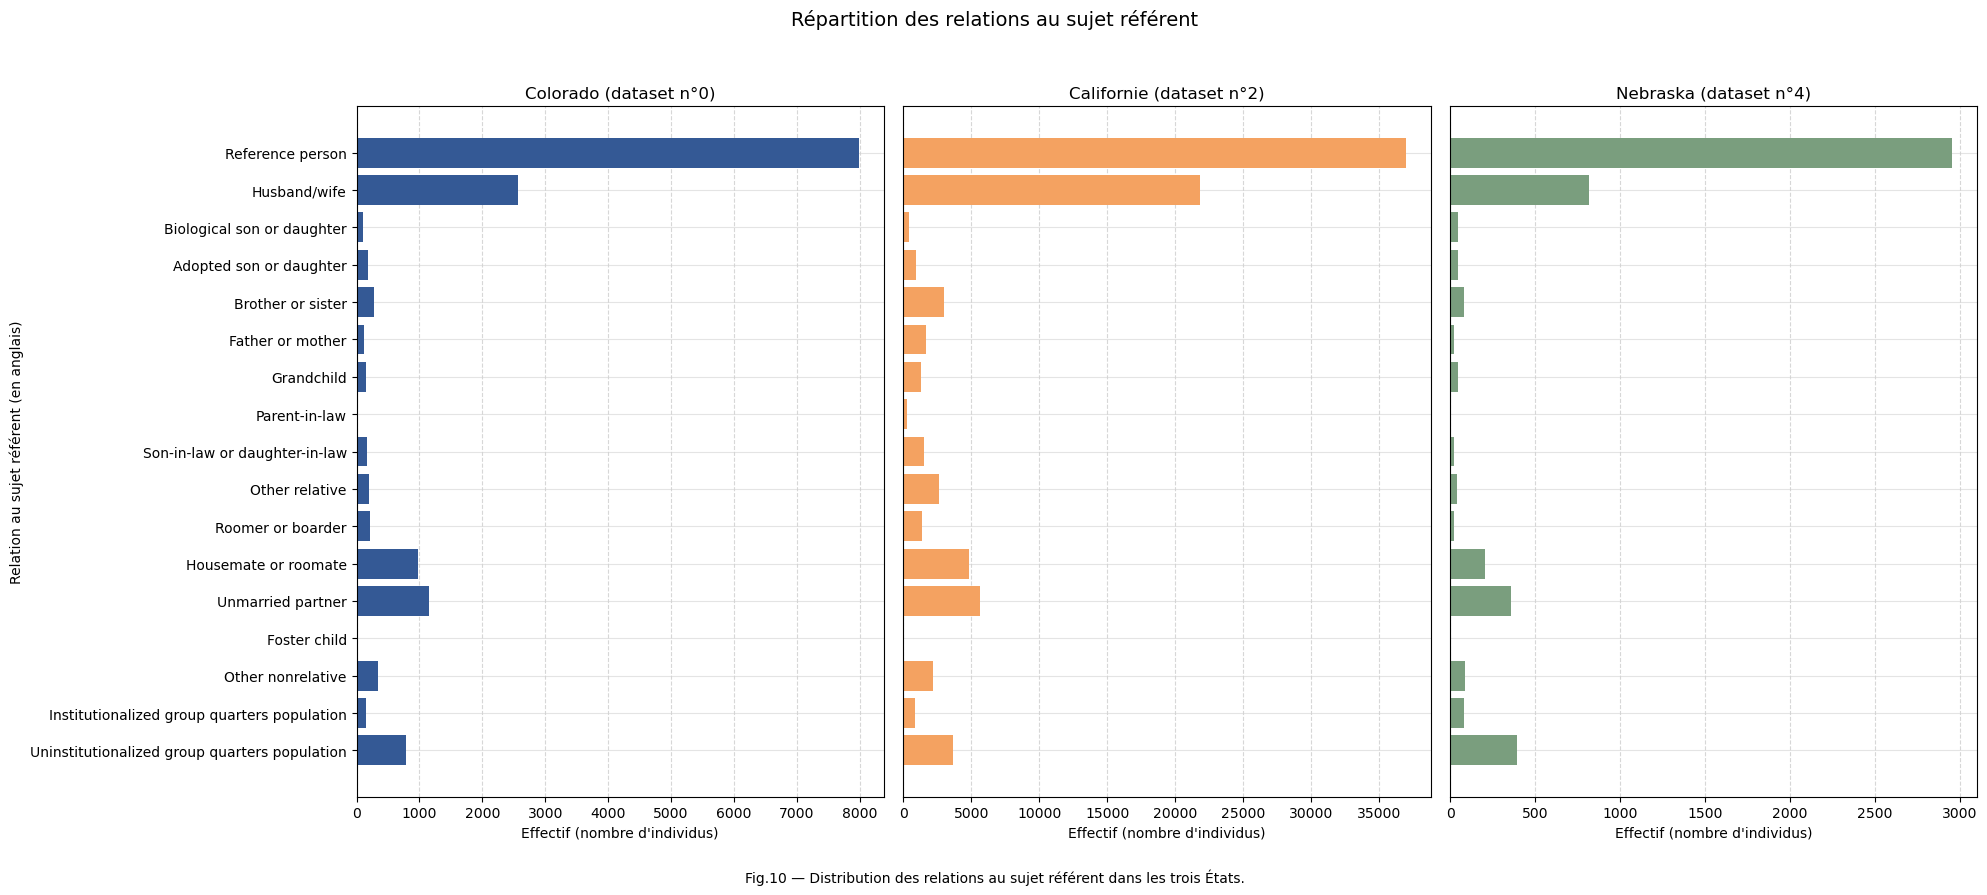

In [39]:
fig, axes = plt.subplots(1, 3, figsize=(20, 9), sharey=True)

colonne = "RELP"

axe_x = {
    1.0: "Reference person",
    2.0: "Husband/wife",
    3.0: "Biological son or daughter",
    4.0: "Adopted son or daughter",
    5.0: "Brother or sister",
    6.0: "Father or mother",
    7.0: "Grandchild",
    8.0: "Parent-in-law",
    9.0: "Son-in-law or daughter-in-law",
    10.0: "Other relative",
    11.0: "Roomer or boarder",
    12.0: "Housemate or roomate",
    13.0: "Unmarried partner",
    14.0: "Foster child",
    15.0: "Other nonrelative",
    16.0: "Institutionalized group quarters population",
    17.0: "Uninstitutionalized group quarters population"
}

# Conserver toutes les catégories dans le même ordre
categories = list(axe_x.keys())
labels = list(axe_x.values())
positions = range(len(categories))

for j, (ax, df, titre, couleur) in enumerate(
    zip(axes, [datasets[0], datasets[2], datasets[4]], titres, couleurs)
):
    effectifs = df[colonne].value_counts().reindex(categories, fill_value=0)

    ax.barh(positions, effectifs.values, color=couleur)

    ax.set_title(titre)
    ax.set_xlabel("Effectif (nombre d'individus)")
    ax.grid(axis="x", linestyle="--", alpha=0.5)
    ax.set_axisbelow(True)
    ax.grid(axis="y", color="lightgray", linestyle="-", alpha=0.6)


    # Afficher les noms uniquement à gauche
    ax.set_yticks(list(positions))
    if j == 0:
        ax.set_yticklabels(labels)
        ax.set_ylabel("Relation au sujet référent (en anglais)")

    else:
        ax.tick_params(axis="y", left=False, labelleft=False)

# Inverser l'ordre pour afficher la catégorie 1 en haut
axes[0].invert_yaxis()

fig.suptitle("Répartition des relations au sujet référent", fontsize=14)
fig.text(
    0.5, 0.01,
    "Fig.10 — Distribution des relations au sujet référent dans les trois États.",
    ha="center"
)

plt.tight_layout(rect=[0, 0.04, 1, 0.95])
plt.show()

On observe dans la figure Fig.10 une similarité dans la distribution des relations à la personne référente dans les trois États.

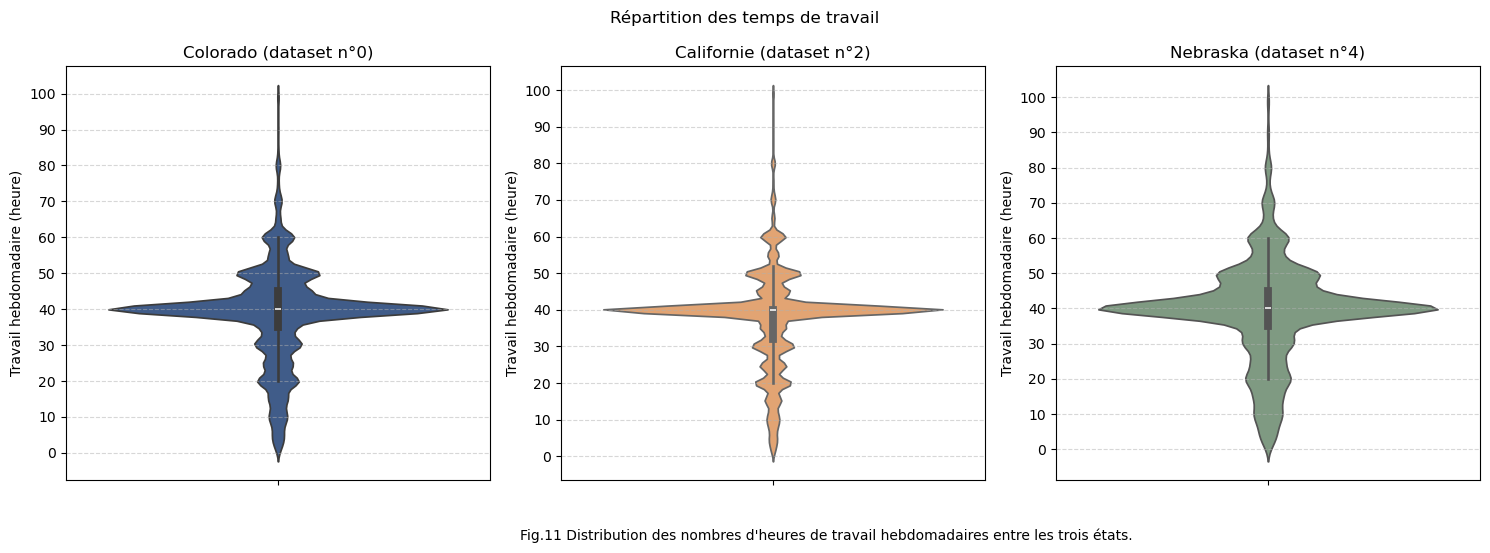

In [29]:
##

fig, axes = plt.subplots(1, 3, figsize=(15, 5))

colonne = "WKHP"

for ax, df, titre, couleur in zip(axes, [datasets[0], datasets[2], datasets[4]], titres, couleurs):
    sns.violinplot(y=df[colonne], ax=ax, color = couleur)
    ax.set_title(titre)
    ax.set_ylabel("Travail hebdomadaire (heure)")
    ax.grid(axis="y", linestyle="--", alpha=0.5)
    ax.set_yticks(range(0, 101, 10))

fig.suptitle("Répartition des temps de travail")
fig.text(0.35, -0.08, "Fig.11 Distribution des nombres d'heures de travail hebdomadaires entre les trois états.")

plt.tight_layout()
plt.show()

On peut observer une meilleure ressemblance entre les distributions des temps de travail hebdomadaire entre le Colorado et le Nebraska qu'avec la Californie sur la figure Fig.11.

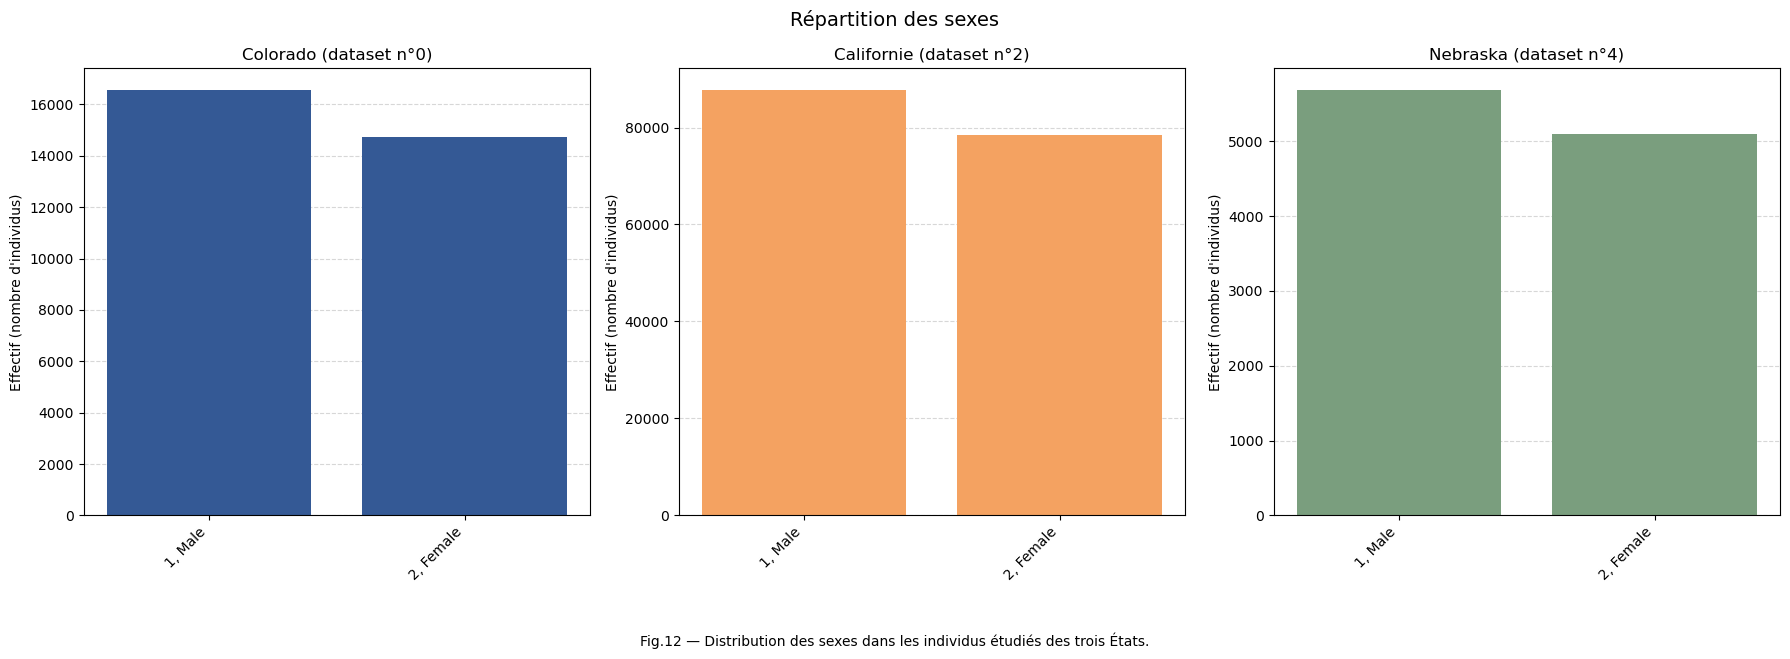

In [30]:
fig, axes = plt.subplots(1, 3, figsize=(18, 6))

colonne = "SEX"

axe_x = {
    1.0: "1, Male",
    2.0: "2, Female"
}

for ax, df, titre, couleur in zip(
    axes, [datasets[0], datasets[2], datasets[4]], titres, couleurs
):
    effectifs = df[colonne].value_counts().sort_index()
    labels = [axe_x.get(x, str(x)) for x in effectifs.index]

    ax.bar(range(len(effectifs)), effectifs.values, color = couleur)

    ax.set_xticks(range(len(effectifs)))
    ax.set_xticklabels(labels, rotation=45, ha="right")

    ax.set_title(titre)
    ax.set_ylabel("Effectif (nombre d'individus)")
    ax.grid(axis="y", linestyle="--", alpha=0.5)
    ax.set_axisbelow(True)

fig.suptitle("Répartition des sexes", fontsize=14)
fig.text(0.5, -0.08, "Fig.12 — Distribution des sexes dans les individus étudiés des trois États.", ha="center")

plt.tight_layout()
plt.show()

La figure Fig.12 nous montre que la répartition des sexes des individus étudiés est quasiment identique dans les trois jeux de données.

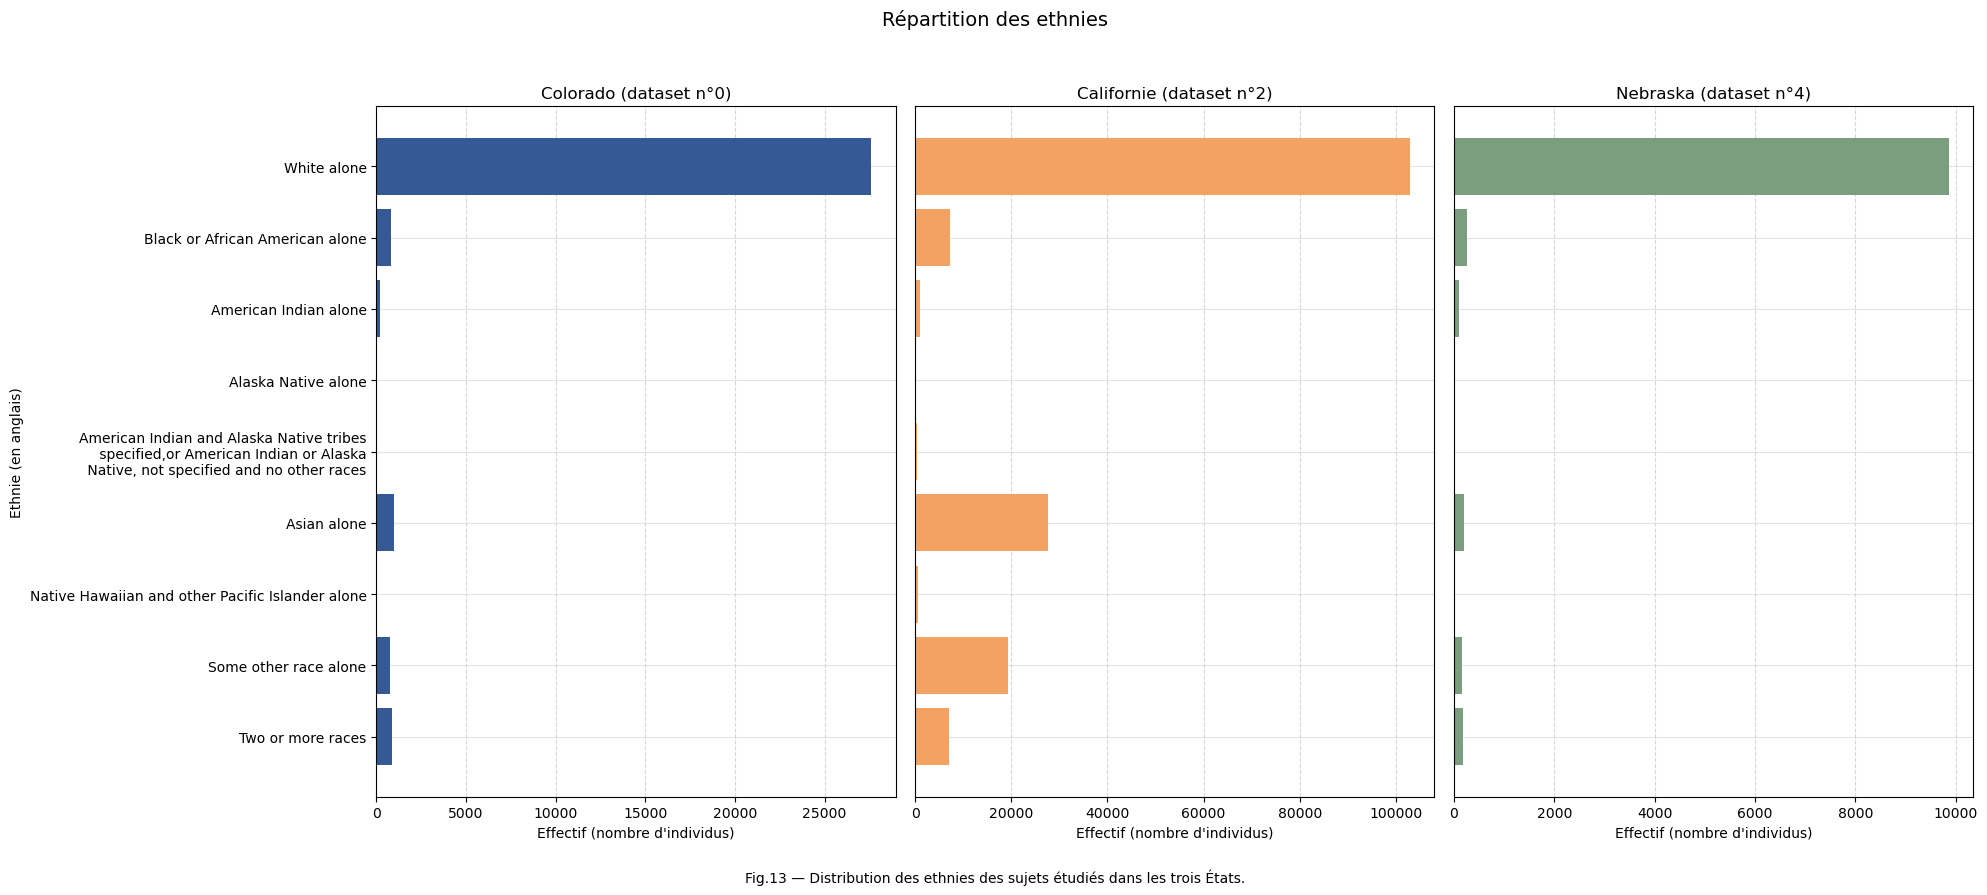

In [31]:
fig, axes = plt.subplots(1, 3, figsize=(20, 9), sharey=True)

colonne = "RAC1P"

axe_x = {
    1.0: "White alone",
    2.0: "Black or African American alone",
    3.0: "American Indian alone",
    4.0: "Alaska Native alone",
    5.0: "American Indian and Alaska Native tribes\n specified,or American Indian or Alaska\n Native, not specified and no other races",
    6.0: "Asian alone",
    7.0: "Native Hawaiian and other Pacific Islander alone",
    8.0: "Some other race alone",
    9.0: "Two or more races"
}

# Conserver toutes les catégories dans le même ordre
categories = list(axe_x.keys())
labels = list(axe_x.values())
positions = range(len(categories))

for j, (ax, df, titre, couleur) in enumerate(
    zip(axes, [datasets[0], datasets[2], datasets[4]], titres, couleurs)
):
    effectifs = df[colonne].value_counts().reindex(categories, fill_value=0)

    ax.barh(positions, effectifs.values, color=couleur)

    ax.set_title(titre)
    ax.set_xlabel("Effectif (nombre d'individus)")
    ax.grid(axis="x", linestyle="--", alpha=0.5)
    ax.set_axisbelow(True)
    ax.grid(axis="y", color="lightgray", linestyle="-", alpha=0.6)


    # Afficher les noms uniquement à gauche
    ax.set_yticks(list(positions))
    if j == 0:
        ax.set_yticklabels(labels)
        ax.set_ylabel("Ethnie (en anglais)")

    else:
        ax.tick_params(axis="y", left=False, labelleft=False)

# Inverser l'ordre pour afficher la catégorie 1 en haut
axes[0].invert_yaxis()

fig.suptitle("Répartition des ethnies", fontsize=14)
fig.text(
    0.5, 0.01,
    "Fig.13 — Distribution des ethnies des sujets étudiés dans les trois États.",
    ha="center"
)

plt.tight_layout(rect=[0, 0.04, 1, 0.95])
plt.show()

On remarque dans la figure Fig.13 une quantité bien plus importante d'individus d'ethnies asiatique et autre en Californie que dans les deux autres États.

De plus, nous avons observé dans la figure Fig.3 qu'il n'y a pas de différence majeure dans la répartition entre les individus ayant un revenu annuel supérieur ou inférieur à 50000 dollars entre les trois États.

<h2>IV. Analyse Bivariée et Multivariée</h2>

Nous décidons maintenant d'étudier l'existence de corrélations entre certaines des variables. Nous hypothétisons qu'il peut exister une corrélation entre les features: 
- nOCCP (type d'emploi) avec COW (catégorie d'emploi), SCHL (niveau d'éducation ou WKHP (nombre d'heures de travail hebdomadaire) ;
- nPOBP (région de naissance) et RAC1P (ethnie) ;
- SCHL (niveau d'éducation) et AGEP (âge) ;
- SEX (sexe) avec MAR (statut marital) ou RELP (relation au référent).

Nous étudierons ensuite les corrélations possibles de chaque feature avec le revenu (PINCP).

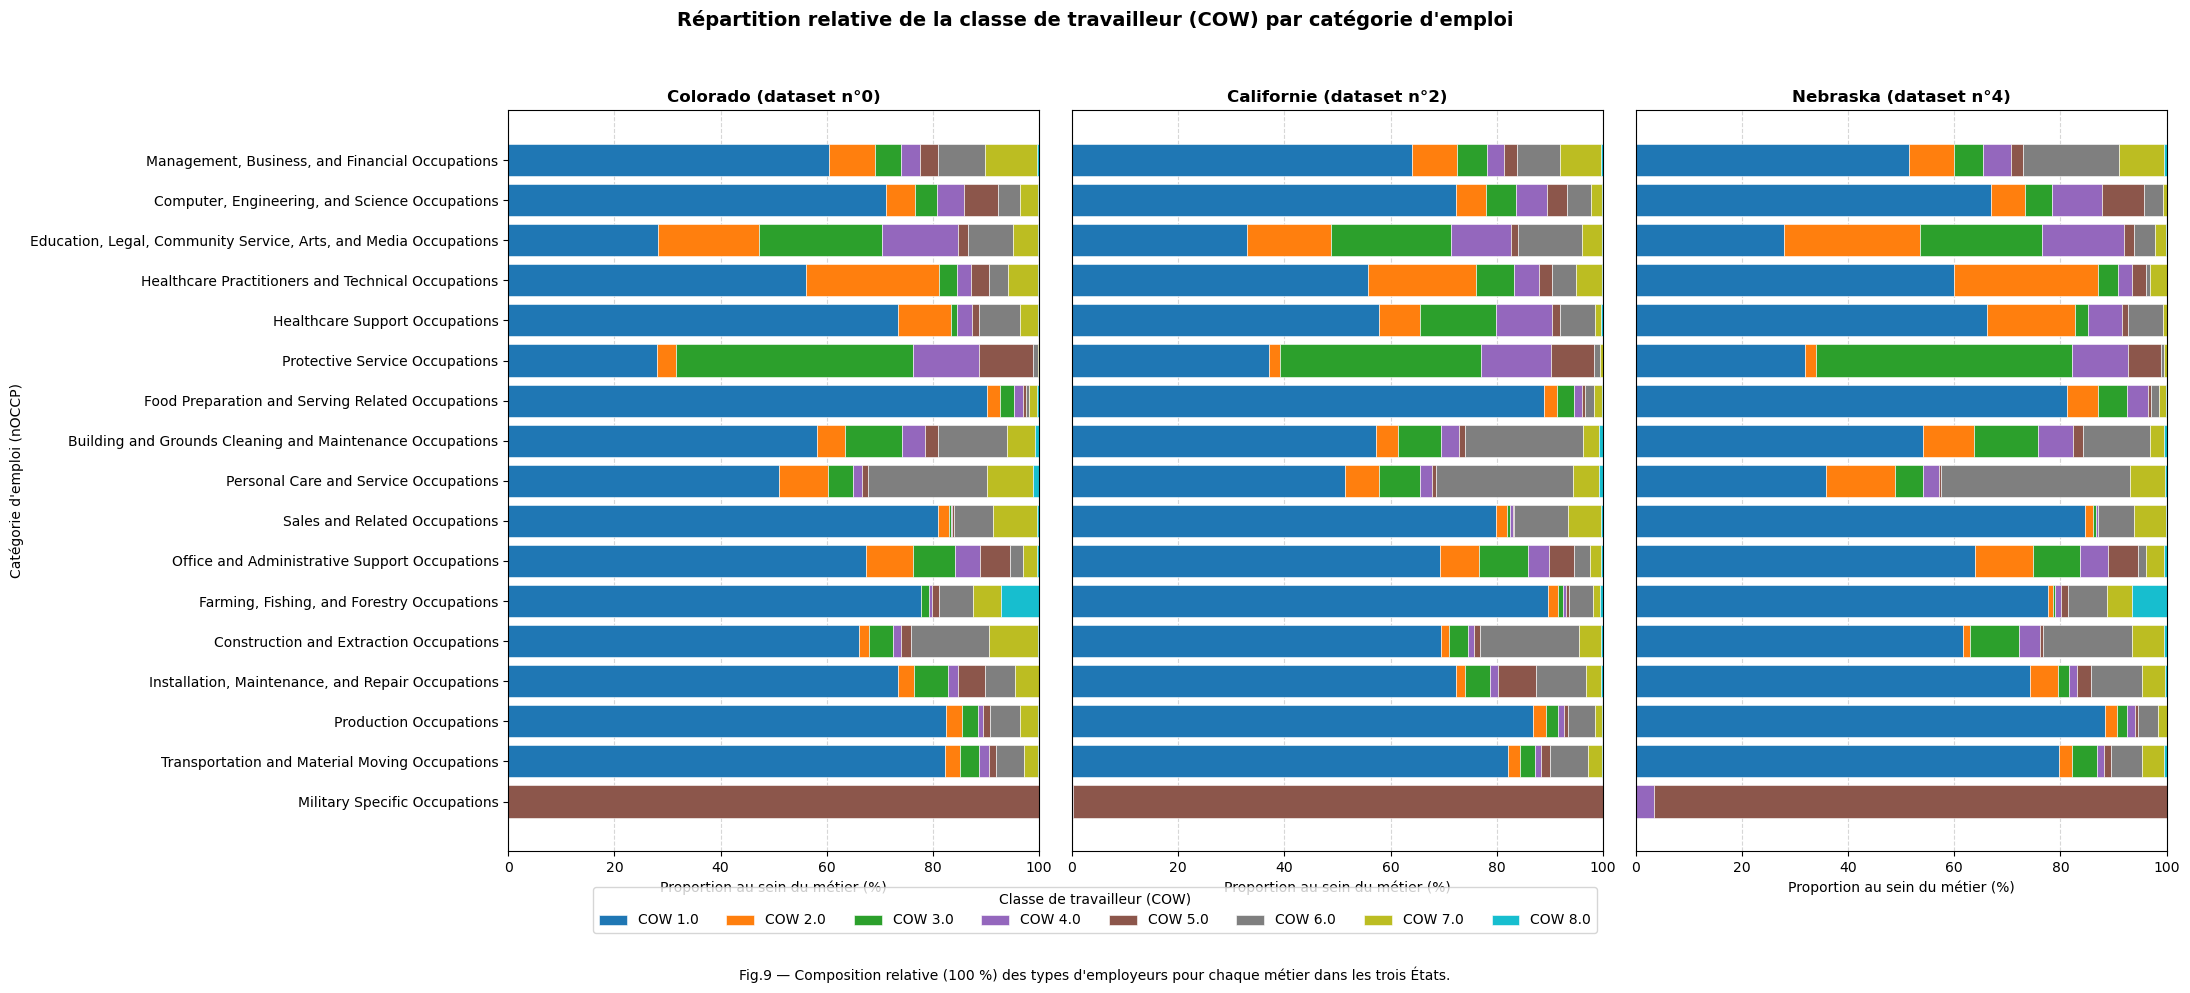

In [41]:
# 1. Dictionnaire et labels pour nOCCP
colonne_y = "nOCCP"
colonne_couleur = "COW"

axe_y = {
    i: nom
    for i, nom in enumerate(census_occupation_subcategories_2018.keys(), start=1)
}
categories = list(axe_y.keys())
labels = list(axe_y.values())
positions = np.arange(len(categories))

# Modalités COW uniques et palette de couleurs distincte
categories_cow = sorted(datasets[0][colonne_couleur].dropna().unique())
# Palette tab10 ou Set1 adaptée pour distinguer jusqu'à 8-9 catégories
couleurs_cow = plt.cm.tab10(np.linspace(0, 1, len(categories_cow)))

fig, axes = plt.subplots(1, 3, figsize=(22, 10), sharey=True)

for j, (ax, df, titre) in enumerate(
    zip(axes, [datasets[0], datasets[2], datasets[4]], titres)
):
    # Tableau de contingence (effectifs par nOCCP et par COW)
    tableau = (
        pd.crosstab(df[colonne_y], df[colonne_couleur])
        .reindex(index=categories, columns=categories_cow, fill_value=0)
    )

    # Normalisation par ligne (somme = 100% pour chaque métier)
    proportions = tableau.div(tableau.sum(axis=1).replace(0, 1), axis=0) * 100

    # Empilement horizontal des barres
    gauche = np.zeros(len(categories))
    for cow_val, couleur in zip(categories_cow, couleurs_cow):
        valeurs = proportions[cow_val].values
        ax.barh(
            positions,
            valeurs,
            left=gauche,
            color=couleur,
            edgecolor="white",
            linewidth=0.4,
            label=f"COW {cow_val}",
        )
        gauche += valeurs

    ax.set_title(titre, fontsize=12, fontweight="bold")
    ax.set_xlabel("Proportion au sein du métier (%)")
    ax.set_xlim(0, 100)
    ax.grid(axis="x", linestyle="--", alpha=0.5)
    ax.set_axisbelow(True)

    # Graduations en Y
    ax.set_yticks(list(positions))
    if j == 0:
        ax.set_yticklabels(labels)
        ax.set_ylabel("Catégorie d'emploi (nOCCP)")
    else:
        ax.tick_params(axis="y", left=False, labelleft=False)

# Inverser pour avoir la première catégorie en haut
axes[0].invert_yaxis()

# Légende unique placée sous les graphiques
handles, labels_legende = axes[0].get_legend_handles_labels()
fig.legend(
    handles,
    labels_legende,
    loc="lower center",
    ncol=len(categories_cow),
    bbox_to_anchor=(0.5, 0.05),
    frameon=True,
    title="Classe de travailleur (COW)",
)

fig.suptitle(
    "Répartition relative de la classe de travailleur (COW) par catégorie d'emploi",
    fontsize=14,
    fontweight="bold",
)
fig.text(
    0.5,
    0.01,
    "Fig.9 — Composition relative (100 %) des types d'employeurs pour chaque métier dans les trois États.",
    ha="center",
    fontsize=10,
)

plt.tight_layout(rect=[0, 0.08, 1, 0.95])
plt.show()
     

Il y a plusieurs choses à voir. Comme vu plus haut, on voit très bien que le privé lucratif est ultra présent, ce qui peut desservir l'analyse, mais on peut voir que pour les domaines de l'education, le droit, les services sociaux l'art ou les médias. Ces différents métiers font beaucoup intervenir des systèmes (éducations, droit) qui sont publiques (vert/violet) ou même des strutures privées non lucratives (orange)(écoles privés, associations privée non lucrative). Les métiers liés aux services de protections sont aussi beaucoup publiques, ce qui fait que la portion verte est très grande. Bien sûr on peut voir une presque parfaite corrélation entre les métiers spécifiques au domaine militaire, et des emploies de catégorie fédérale. La plupart des autres type d'emploies proviennent du lucratif privé et les autres types d'emploies ne s'explicite pas tant que ça.

De plus, les différences entre les états se voient assez peu, même si on peut voir que le bénévolat en Californie dans les domaines de l'agriculture, la pêche ou la sylviculture ressort un peu dans les états du Nebraska ou du Colorado, mais en Californie beaucoup moins. On peut expliquer par le fait qu'en Californie, le style de vie est beaucoup plus accélérée, car c'est une région plus touristique et mondialisée, ou par un biais de donnée. C'est une proportion, mais la quantité de donnée est beaucoup plus importante en Californie, donc on noie un peu celles sur les bénévoles, ou dans l'autre sens la quantité de donnée des autres états permet de montrer ces bénévoles là sans pour autant que ça soit une réalité.

**Pertinent de faire une graphe inverse ? Genre pour chaque cow, découper les catégorie de métier ?**

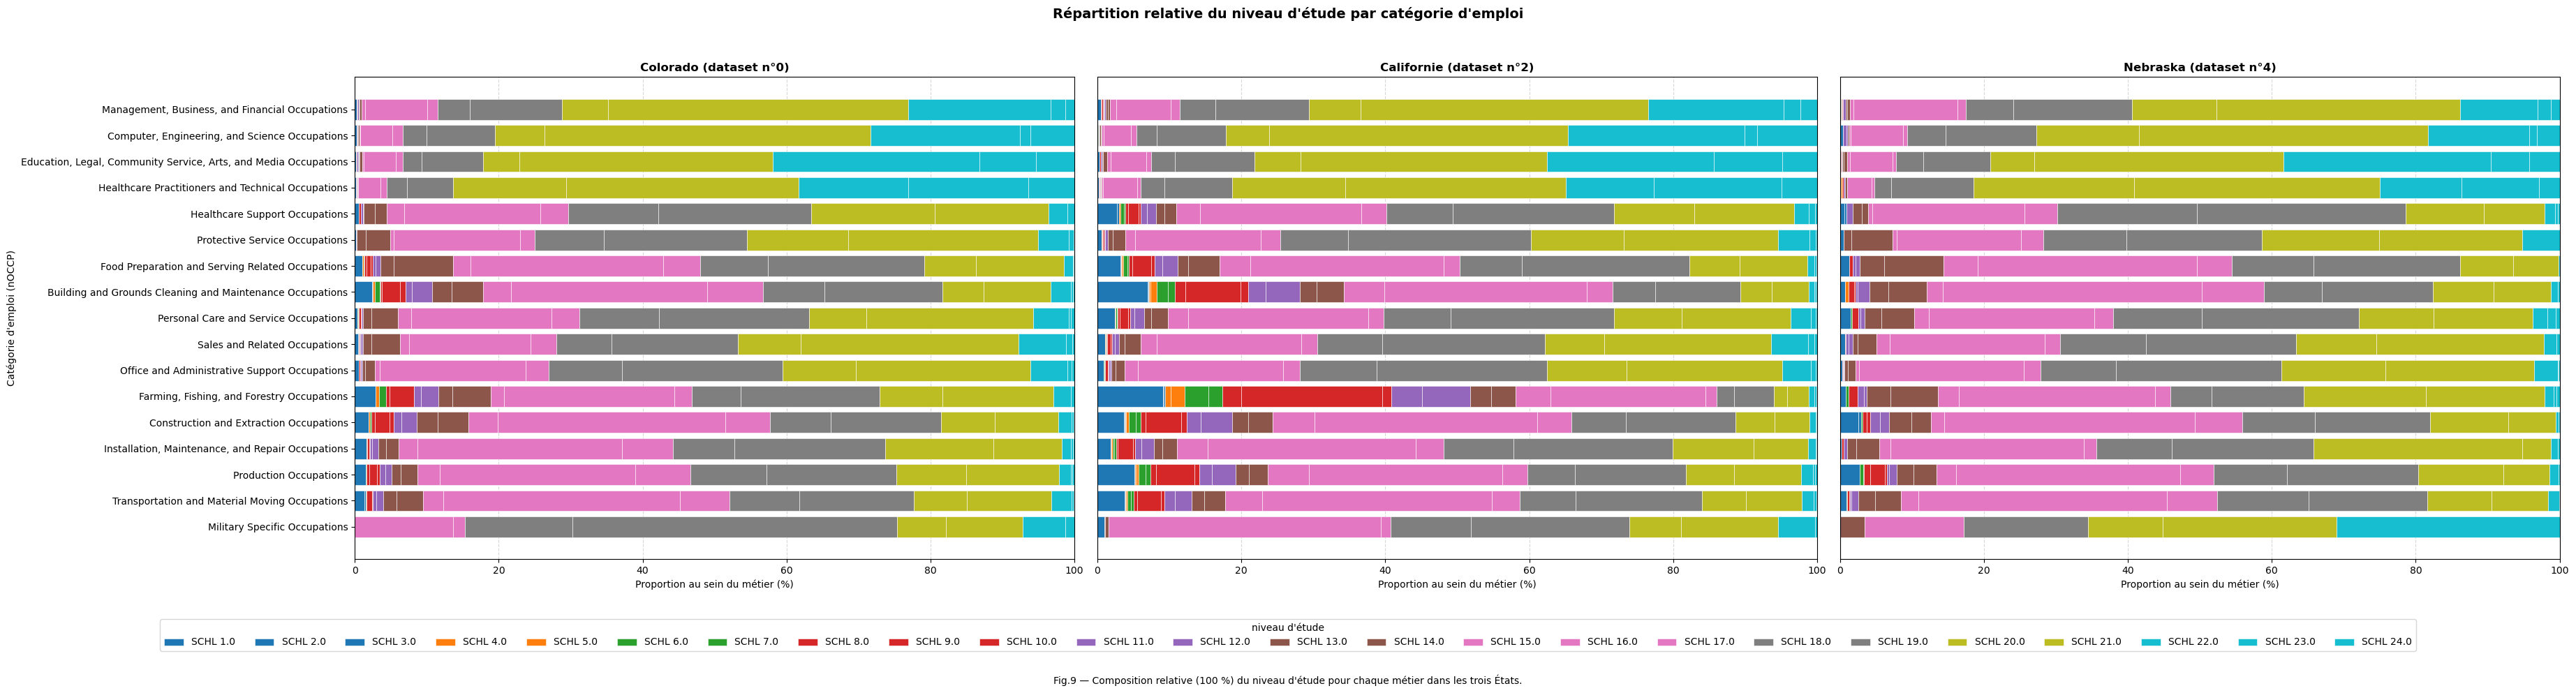

In [54]:
colonne_y = "nOCCP"
colonne_couleur = "SCHL"

axe_y = {
    i: nom
    for i, nom in enumerate(census_occupation_subcategories_2018.keys(), start=1)
}

categories = list(axe_y.keys())
labels = list(axe_y.values())
positions = np.arange(len(categories))

categories_schl = sorted(datasets[0][colonne_couleur].dropna().unique())
couleurs_schl = plt.cm.tab10(np.linspace(0, 1, len(categories_schl)))

fig, axes = plt.subplots(1, 3, figsize=(37, 10), sharey=True)

for j, (ax, df, titre) in enumerate(
    zip(axes, [datasets[0], datasets[2], datasets[4]], titres)
):
    # Tableau de contingence (effectifs par nOCCP et par SCHL)
    tableau = (
        pd.crosstab(df[colonne_y], df[colonne_couleur])
        .reindex(index=categories, columns=categories_schl, fill_value=0)
    )

    # Normalisation par ligne (somme = 100% pour chaque métier)
    proportions = tableau.div(tableau.sum(axis=1).replace(0, 1), axis=0) * 100

    # Empilement horizontal des barres
    gauche = np.zeros(len(categories))
    for cow_val, couleur in zip(categories_schl, couleurs_schl):
        valeurs = proportions[cow_val].values
        ax.barh(
            positions,
            valeurs,
            left=gauche,
            color=couleur,
            edgecolor="white",
            linewidth=0.4,
            label=f"SCHL {cow_val}",
        )
        gauche += valeurs

    ax.set_title(titre, fontsize=12, fontweight="bold")
    ax.set_xlabel("Proportion au sein du métier (%)")
    ax.set_xlim(0, 100)
    ax.grid(axis="x", linestyle="--", alpha=0.5)
    ax.set_axisbelow(True)

    # Graduations en Y
    ax.set_yticks(list(positions))
    if j == 0:
        ax.set_yticklabels(labels)
        ax.set_ylabel("Catégorie d'emploi (nOCCP)")
    else:
        ax.tick_params(axis="y", left=False, labelleft=False)

# Inverser pour avoir la première catégorie en haut
axes[0].invert_yaxis()

# Légende unique placée sous les graphiques
handles, labels_legende = axes[0].get_legend_handles_labels()

fig.legend(
    handles,
    labels_legende,
    loc="lower center",
    ncol=len(categories_cow),
    bbox_to_anchor=(0.5, 0.05),
    frameon=True,
    title="niveau d'étude",
)

fig.suptitle(
    "Répartition relative du niveau d'étude par catégorie d'emploi",
    fontsize=14,
    fontweight="bold",
)
fig.text(
    0.5,
    0.01,
    "Fig.9 — Composition relative (100 %) du niveau d'étude pour chaque métier dans les trois États.",
    ha="center",
    fontsize=10,
)

plt.tight_layout(rect=[0, 0.13, 1, 0.95])
plt.show()

Les compositions sont assez similaires entre les états, avec quelques différences quand même. On peut cependant trouver d'autres corrélations. Les métiers liées aux 4 premières catégories sont essentiellement des métiers dont les personnes ont un diplome type bachelor/DUT, et une bonne partie possède un master qui est un élément distinguant par rapport aux catégories du soin aux personnes et celui de la vente, ou la grande majorité (~95%) des travailleurs ont 1 à 3 années d'étude. Sinon, dans les autres catégories d'emplois, la place que prennent les personnes ayant le BAC (équivalent américain) comme plus haut niveau d'étude sont assez présent, avec aux alentours des 50 % à chaque fois. J'apporte une attention particulière aux domaines de la construction ou de l'entretien, car les niveaux d'études sont extrêmement bas, surtout pour la Califronie ou une bonne partie des personnes ont arrêter l'école bien avant la fin du lycée (4-5 ans avant). On peut donc supposée une beaucoup plus grande pauvreté dans ces types de métiers, dont souvent les personnes qui l'exerce sont des immigrés, qui pourrais aussi expliqué l'accent de ses inégalités en Californie, très marqué par l'immigration via le Mexique.

De plus, on voit que en proportion, il y a moins de diplomés de Master et Doctorat dans le Nebraska que dans les 2 autres états.

/tmp/ipykernel_5906/2483386019.py:23: FutureWarning: 

The `scale` parameter has been renamed and will be removed in v0.15.0. Pass `density_norm='width'` for the same effect.
  sns.violinplot(
/tmp/ipykernel_5906/2483386019.py:23: FutureWarning: 

The `scale` parameter has been renamed and will be removed in v0.15.0. Pass `density_norm='width'` for the same effect.
  sns.violinplot(
/tmp/ipykernel_5906/2483386019.py:23: FutureWarning: 

The `scale` parameter has been renamed and will be removed in v0.15.0. Pass `density_norm='width'` for the same effect.
  sns.violinplot(


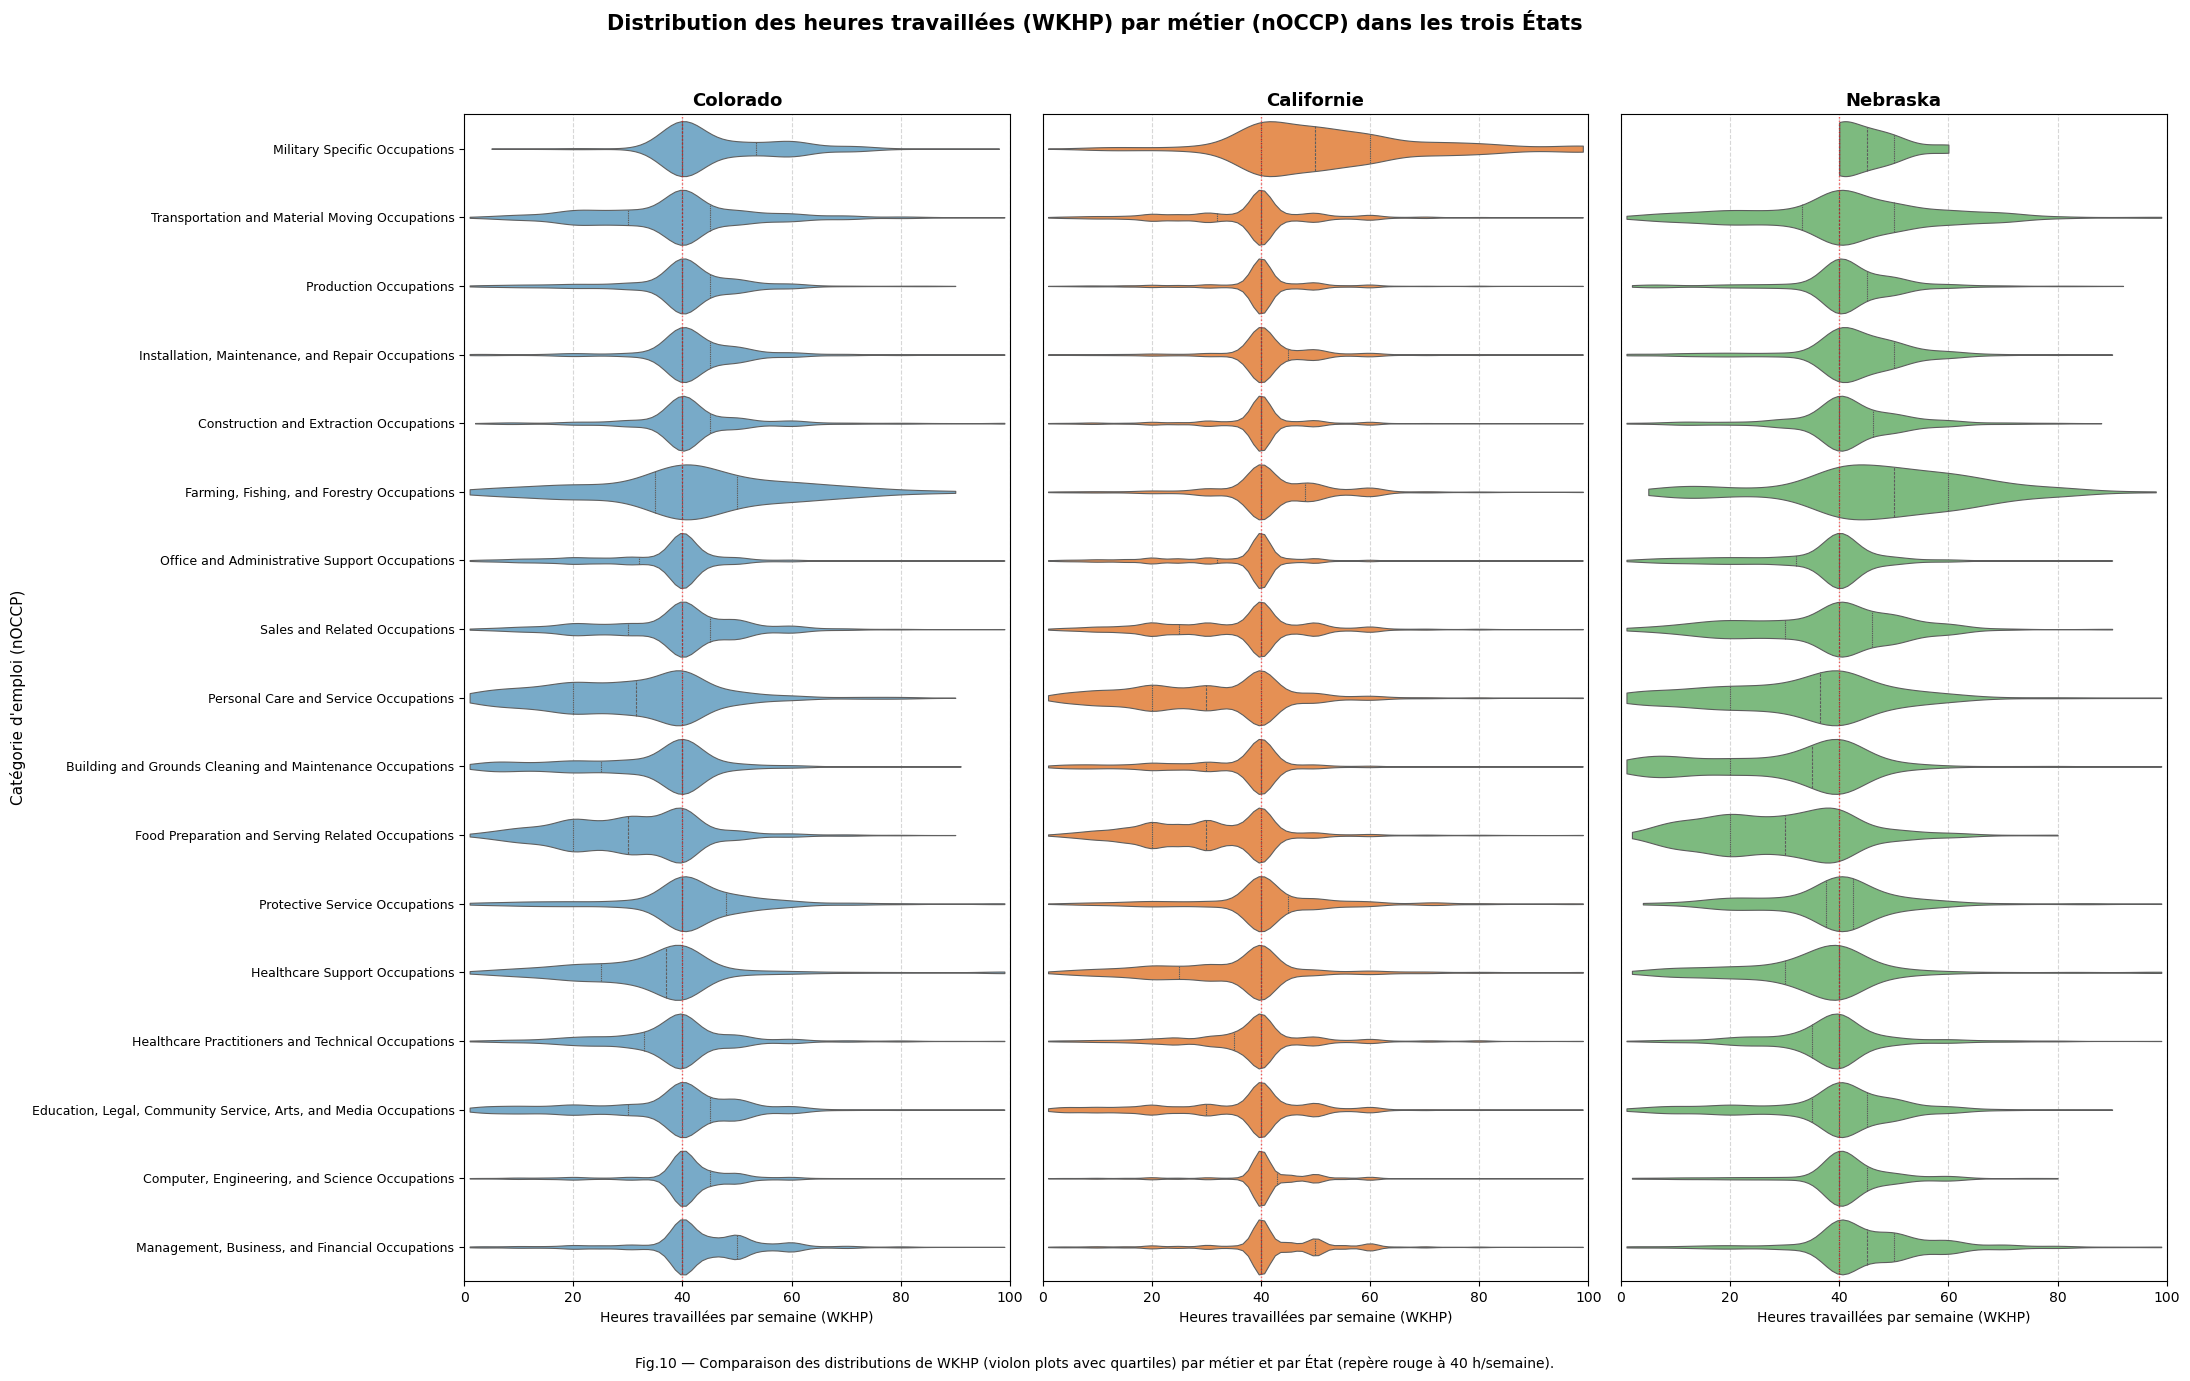

In [56]:
# Préparation des labels
axe_y = {
    i: nom
    for i, nom in enumerate(census_occupation_subcategories_2018.keys(), start=1)
}
categories = list(axe_y.keys())
labels = list(axe_y.values())

etats = [
    (datasets[0], "Colorado", "Blues"),
    (datasets[2], "Californie", "Oranges"),
    (datasets[4], "Nebraska", "Greens"),
]

fig, axes = plt.subplots(1, 3, figsize=(22, 14), sharey=True)

for j, (ax, (df, nom_etat, palette_nom)) in enumerate(zip(axes, etats)):
    # Nettoyage
    df_clean = df.dropna(subset=["nOCCP", "WKHP"]).copy()
    df_clean = df_clean[df_clean["nOCCP"].isin(categories)]

    # Tracé des violons horizontaux
    sns.violinplot(
        data=df_clean,
        x="WKHP",
        y="nOCCP",
        order=categories,
        orient="h",
        ax=ax,
        cut=0,
        inner="quartile",
        linewidth=0.8,
        color=plt.get_cmap(palette_nom)(0.5),
        scale="width",  # Donne la même largeur maximale à chaque violon
    )

    ax.set_title(nom_etat, fontsize=13, fontweight="bold")
    ax.set_xlabel("Heures travaillées par semaine (WKHP)", fontsize=10)
    ax.set_xlim(0, 100)
    ax.grid(axis="x", linestyle="--", alpha=0.5)
    ax.set_axisbelow(True)

    # Ligne verticale de repère pour les 35h et 40h standard
    ax.axvline(40, color="red", linestyle=":", alpha=0.6, linewidth=1)

    # Affichage des étiquettes métiers uniquement à gauche
    if j == 0:
        ax.set_yticks(range(len(categories)))
        ax.set_yticklabels(labels, fontsize=9)
        ax.set_ylabel("Catégorie d'emploi (nOCCP)", fontsize=11)
    else:
        ax.tick_params(axis="y", left=False, labelleft=False)
        ax.set_ylabel("")

# Première catégorie en haut
axes[0].invert_yaxis()

fig.suptitle(
    "Distribution des heures travaillées (WKHP) par métier (nOCCP) dans les trois États",
    fontsize=15,
    fontweight="bold",
    y=0.98,
)
fig.text(
    0.5,
    0.01,
    "Fig.10 — Comparaison des distributions de WKHP (violon plots avec quartiles) par métier et par État (repère rouge à 40 h/semaine).",
    ha="center",
    fontsize=10,
)

plt.tight_layout(rect=[0, 0.03, 1, 0.96])
plt.show()

Blablabla

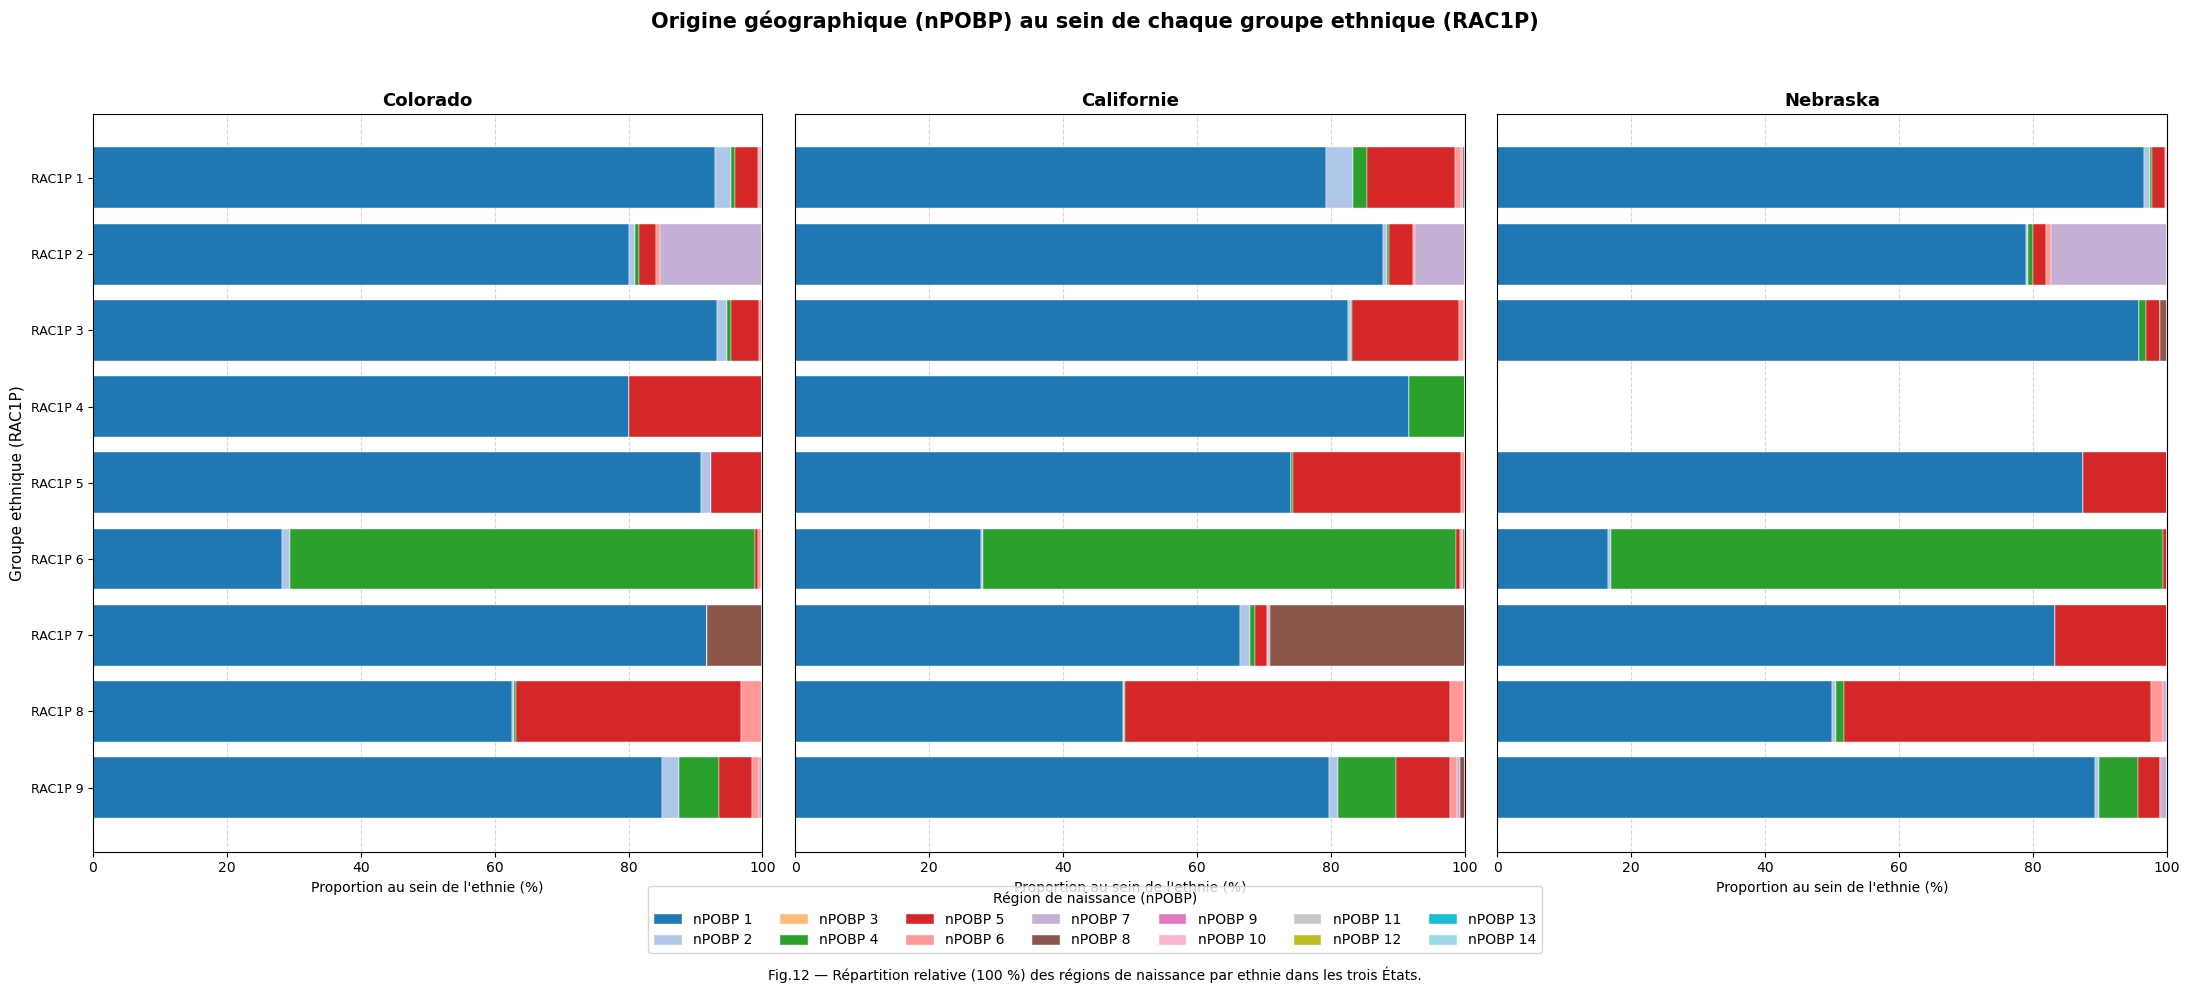

In [86]:
colonne_y = "RAC1P"  # Ethnie en ordonnée
colonne_couleur = "nPOBP"  # Région de naissance en couleurs

categories_rac1p = list(range(1, 10))  # 1 à 9
categories_npobp = list(range(1, 15))  # 1 à 14
positions = np.arange(len(categories_rac1p))

# Palette de 14 couleurs pour nPOBP
couleurs_npobp = plt.cm.tab20(np.linspace(0, 1, len(categories_npobp)))

etats = [
    (datasets[0], "Colorado"),
    (datasets[2], "Californie"),
    (datasets[4], "Nebraska"),
]

fig, axes = plt.subplots(1, 3, figsize=(22, 10), sharey=True)

for j, (ax, (df, nom_etat)) in enumerate(zip(axes, etats)):
    # Tableau croisé : Lignes = Ethnies (RAC1P), Colonnes = Origines (nPOBP)
    tableau = (
        pd.crosstab(df[colonne_y], df[colonne_couleur])
        .reindex(index=categories_rac1p, columns=categories_npobp, fill_value=0)
    )

    # Normalisation à 100 % au sein de chaque groupe ethnique
    proportions = tableau.div(tableau.sum(axis=1).replace(0, 1), axis=0) * 100

    # Empilement horizontal
    gauche = np.zeros(len(categories_rac1p))
    for pob_val, couleur in zip(categories_npobp, couleurs_npobp):
        valeurs = proportions[pob_val].values
        ax.barh(
            positions,
            valeurs,
            left=gauche,
            color=couleur,
            edgecolor="white",
            linewidth=0.3,
            label=f"nPOBP {pob_val}",
        )
        gauche += valeurs

    ax.set_title(nom_etat, fontsize=13, fontweight="bold")
    ax.set_xlabel("Proportion au sein de l'ethnie (%)", fontsize=10)
    ax.set_xlim(0, 100)
    ax.grid(axis="x", linestyle="--", alpha=0.5)
    ax.set_axisbelow(True)

    # Graduations en Y
    ax.set_yticks(positions)
    if j == 0:
        ax.set_yticklabels([f"RAC1P {i}" for i in categories_rac1p], fontsize=9)
        ax.set_ylabel("Groupe ethnique (RAC1P)", fontsize=11)
    else:
        ax.tick_params(axis="y", left=False, labelleft=False)

axes[0].invert_yaxis()

# Légende sous le graphique
handles, labels_legende = axes[0].get_legend_handles_labels()
fig.legend(
    handles,
    labels_legende,
    loc="lower center",
    ncol=7,
    bbox_to_anchor=(0.5, 0.03),
    frameon=True,
    title="Région de naissance (nPOBP)",
)

fig.suptitle(
    "Origine géographique (nPOBP) au sein de chaque groupe ethnique (RAC1P)",
    fontsize=15,
    fontweight="bold",
    y=0.98,
)
fig.text(
    0.5,
    0.01,
    "Fig.12 — Répartition relative (100 %) des régions de naissance par ethnie dans les trois États.",
    ha="center",
    fontsize=10,
)

plt.tight_layout(rect=[0, 0.08, 1, 0.95])
plt.show()

/tmp/ipykernel_5906/1343366731.py:18: FutureWarning: 

The `scale` parameter has been renamed and will be removed in v0.15.0. Pass `density_norm='width'` for the same effect.
  sns.violinplot(
/tmp/ipykernel_5906/1343366731.py:18: FutureWarning: 

The `scale` parameter has been renamed and will be removed in v0.15.0. Pass `density_norm='width'` for the same effect.
  sns.violinplot(
/tmp/ipykernel_5906/1343366731.py:18: FutureWarning: 

The `scale` parameter has been renamed and will be removed in v0.15.0. Pass `density_norm='width'` for the same effect.
  sns.violinplot(


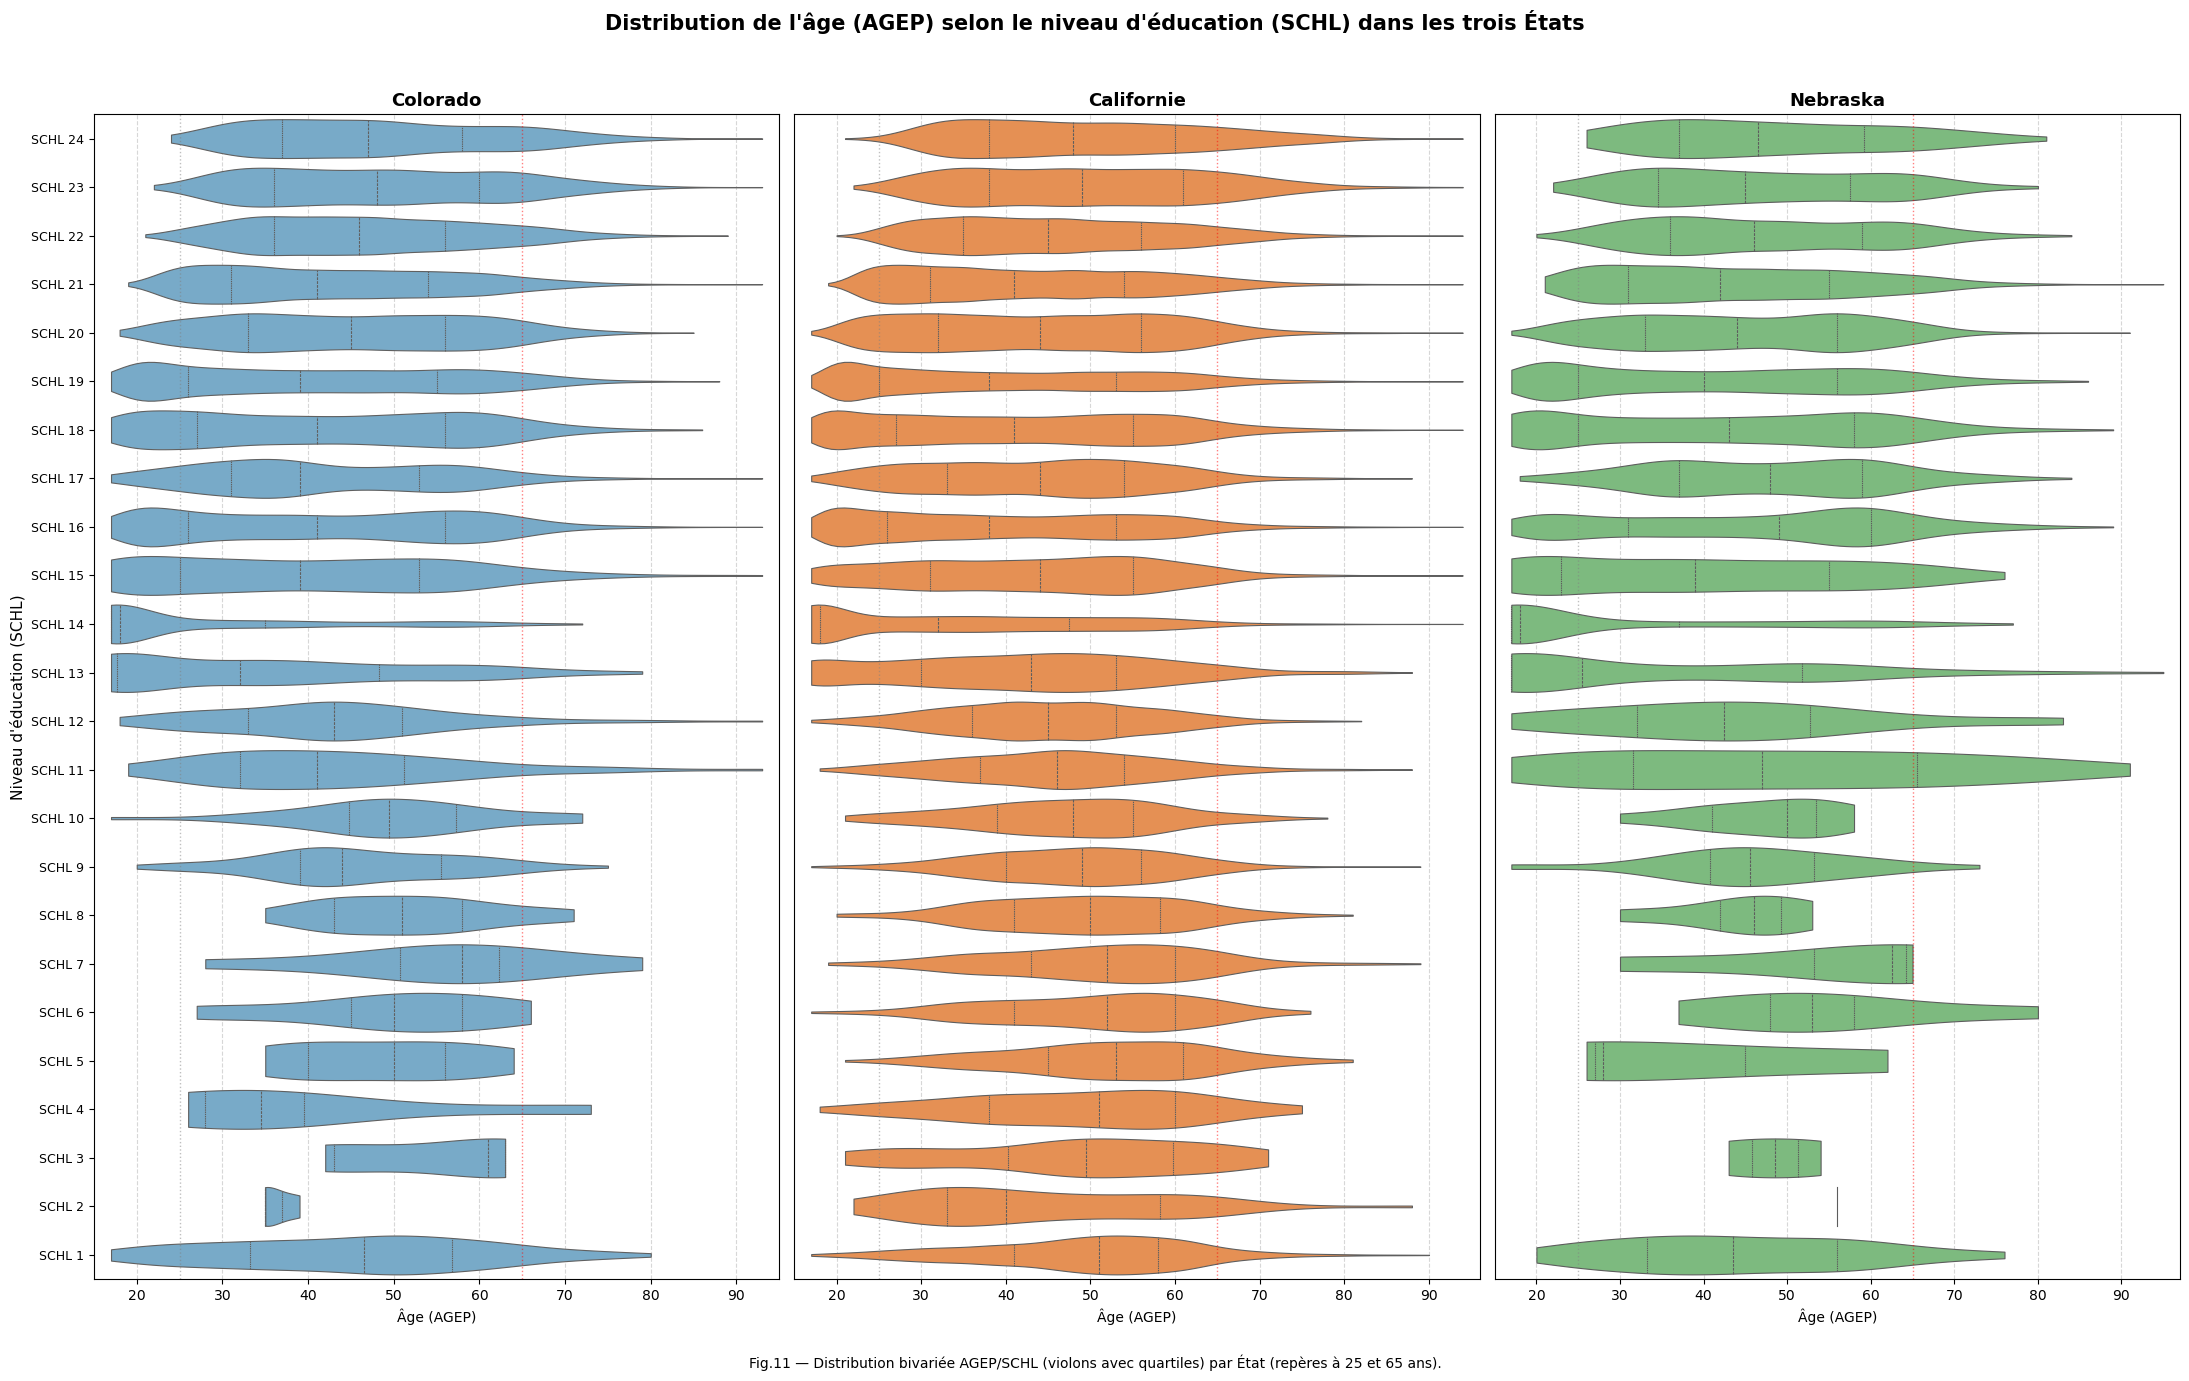

In [84]:

categories_schl = sorted(datasets[0]["SCHL"].dropna().unique())
positions = range(len(categories_schl))

etats = [
    (datasets[0], "Colorado", "Blues"),
    (datasets[2], "Californie", "Oranges"),
    (datasets[4], "Nebraska", "Greens"),
]

fig, axes = plt.subplots(1, 3, figsize=(22, 14), sharey=True)

for j, (ax, (df, nom_etat, palette_nom)) in enumerate(zip(axes, etats)):
    # Nettoyage
    df_clean = df.dropna(subset=["SCHL", "AGEP"]).copy()
    df_clean = df_clean[df_clean["SCHL"].isin(categories_schl)]

    # Tracé des violons horizontaux
    sns.violinplot(
        data=df_clean,
        x="AGEP",
        y="SCHL",
        order=categories_schl,
        orient="h",
        ax=ax,
        cut=0,
        inner="quartile",
        linewidth=0.8,
        color=plt.get_cmap(palette_nom)(0.5),
        scale="width",  # Largeur maximale identique pour chaque niveau de diplôme
    )

    ax.set_title(nom_etat, fontsize=13, fontweight="bold")
    ax.set_xlabel("Âge (AGEP)", fontsize=10)
    ax.set_xlim(df_clean["AGEP"].min() - 2, df_clean["AGEP"].max() + 2)
    ax.grid(axis="x", linestyle="--", alpha=0.5)
    ax.set_axisbelow(True)

    # Repères visuels d'âge usuels (début de carrière / retraite indicative)
    ax.axvline(25, color="gray", linestyle=":", alpha=0.5, linewidth=1)
    ax.axvline(65, color="red", linestyle=":", alpha=0.5, linewidth=1)

    # Affichage des libellés SCHL uniquement sur la colonne de gauche
    if j == 0:
        ax.set_yticks(positions)
        ax.set_yticklabels([f"SCHL {int(c)}" for c in categories_schl], fontsize=9)
        ax.set_ylabel("Niveau d'éducation (SCHL)", fontsize=11)
    else:
        ax.tick_params(axis="y", left=False, labelleft=False)
        ax.set_ylabel("")

# Inverser pour afficher le niveau le plus bas ou le plus haut en premier
axes[0].invert_yaxis()

fig.suptitle(
    "Distribution de l'âge (AGEP) selon le niveau d'éducation (SCHL) dans les trois États",
    fontsize=15,
    fontweight="bold",
    y=0.98,
)
fig.text(
    0.5,
    0.01,
    "Fig.11 — Distribution bivariée AGEP/SCHL (violons avec quartiles) par État (repères à 25 et 65 ans).",
    ha="center",
    fontsize=10,
)

plt.tight_layout(rect=[0, 0.03, 1, 0.96])
plt.show()

In [ ]:
##### !!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!


MAR      [G]
         SEX

##### !!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!

    
RELP     [G]
         SEX

In [ ]:
##### !!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!

Pour chaque feature:
    
    PINCP (violin plot)
         feature

<h2>V. Conclusions</h2>